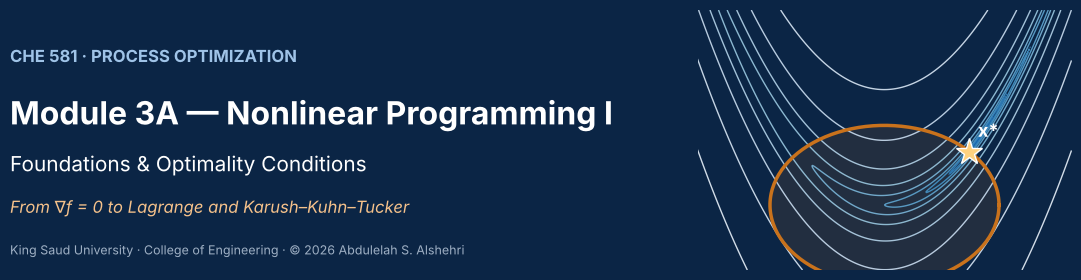

# Module 3A — Nonlinear Programming I
## Foundations & Optimality Conditions
### CHE 581: Process Optimization
**College of Engineering — King Saud University** · Department of Chemical Engineering · Instructor: **Abdulelah S. Alshehri**

> **How to use this notebook**
> - **Colab / Jupyter:** run the setup cell first (or *Run all*). GIFs play automatically, and the slider plots become interactive.
> - **Present as slides:** in Jupyter with the RISE extension press `Alt + R`, or run
>   `jupyter nbconvert Module03A_Lecture.ipynb --to slides --SlidesExporter.reveal_scroll=True --post serve`

<sub>© 2026 Abdulelah S. Alshehri. All rights reserved.</sub>

In [ ]:
# ⚙️ Setup: run this cell first (it is hidden in slide mode)
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
import itertools, warnings; warnings.filterwarnings("ignore")
try:                                   # sliders work in Colab / Jupyter with ipywidgets
    from ipywidgets import interact, FloatSlider, IntSlider
    HAS_WIDGETS = True
except ImportError:                    # otherwise we simply draw a static plot
    HAS_WIDGETS = False

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(581)       # fixed seed → everyone gets the same numbers
NAVY, BLUE, GOLD, TEAL, RED, PURPLE, GRAY = "#0B2545", "#1F6FB2", "#C9721C", "#109C8F", "#C93C3C", "#7B4FA0", "#8D99AE"
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
print("✅ Setup complete — NumPy", np.__version__, "· SymPy", sp.__version__)

✅ Setup complete — NumPy 2.1.3 · SymPy 1.14.0


##  Roadmap & Learning Outcomes

| Part | Slides | Topics |
|---|---|---|
| **A · What is an NLP?** | 1 – 5 | the nonlinear world, problem statement, LP vs. NLP geometry, process applications, the pooling problem |
| **B · Unconstrained optimization** | 6 – 9 | optimality conditions, Newton's method, convergence rates, quasi-Newton (BFGS) |
| **C · Equality constraints** | 10 – 13 | Lagrangian, first- and second-order conditions, optimal tank design |
| **D · Inequality constraints & KKT** | 14 – 18 | active sets, the KKT conditions, shadow prices, constraint qualification |
| **E · Convexity & solving KKT** | 19 – 22 | global optimality, the active-set procedure, the non-convex pooling trap |

**By the end of this lecture you will be able to:**
1. Recognize and formulate an **NLP** and count its **degrees of freedom**.
2. Use **first- and second-order conditions** to find and classify stationary points.
3. Explain **Newton** and **quasi-Newton (BFGS)** methods and compare their **convergence rates**.
4. Write the **Lagrangian** and the **KKT conditions** for any NLP and read multipliers as **shadow prices**.
5. Check a **constraint qualification** and use **convexity** to certify a **global** optimum.
6. Find KKT points with the **active-set procedure** and recognize **non-convex** traps.

# Part A
## What is a Nonlinear Program?
### *"But we all know the world is nonlinear!"*

## 1 · The world is nonlinear

**July 1948.** A young George Dantzig presents *linear programming* to an audience that includes Hotelling, Koopmans and von Neumann. Harold Hotelling stands up: ***"But we all know the world is nonlinear!"*** Von Neumann came to Dantzig's rescue: if your problem satisfies the assumptions, use LP; if it does not, don't.

Process models break the linear assumptions almost everywhere:

| Source of nonlinearity | 🛠️ Process example | Mathematical form |
|---|---|---|
| Phase equilibrium | $y_i = K_i(T,P)\,x_i$ on every distillation tray | product of variables, nonlinear $K$ |
| Reaction kinetics | Arrhenius $k = k_0\,e^{-E/RT}$ | exponential |
| Energy balances | $Q = F\,c_p\,(T_{out} - T_{in})$ with $F$ and $T$ both free | bilinear $F \cdot T$ |
| Economies of scale | equipment cost $C = C_0\,(S/S_0)^{0.6}$ | concave power law |
| Blending / pooling | pool quality × outlet flow | bilinear $q \cdot f$ |
| Fluid flow | pressure drop $\Delta P \propto v^2$ | quadratic |

>  The moment **any** function in the model curves, you are doing **nonlinear programming (NLP)**.

## 2 · The general nonlinear programming problem

$$\min_{x \in \mathbb{R}^n} \; f(x)$$
$$\text{s.t.} \qquad h(x) = 0 \;\; (m \text{ equalities}), \qquad g(x) \le 0 \;\; (p \text{ inequalities}), \qquad x \in X$$

- It is an **NLP** if **at least one** of $f, g, h$ is nonlinear and the variables $x$ are **continuous** (integer variables come later in the course).
- **Degrees of freedom** $= n - m$. We need $m < n$; if $m = n$ the equations fix $x$ and there is nothing left to optimize.

| Standard-form trick | Example |
|---|---|
| $\max f(x) \;\Leftrightarrow\; \min\, -f(x)$ | maximize profit = minimize (−profit) |
| inequality → equality with a **slack** $s \ge 0$ | $x_1 x_2 \le 10 \;\Rightarrow\; x_1 x_2 + s = 10,\; s \ge 0$ |
| free variable → two nonnegative ones | $z \in \mathbb{R} \;\Rightarrow\; z = x - y,\; x, y \ge 0$ |

**A short history:** Lagrange (equalities, 1788) → **Karush (1939), Kuhn & Tucker (1951)** (inequalities) → Powell (SQP, 1977), Murtagh & Saunders (MINOS, 1978), Nocedal (quasi-Newton, L-BFGS), Biegler & Wächter (IPOPT, 2000s).

## 3 · LP vs. NLP: where can the optimum be?

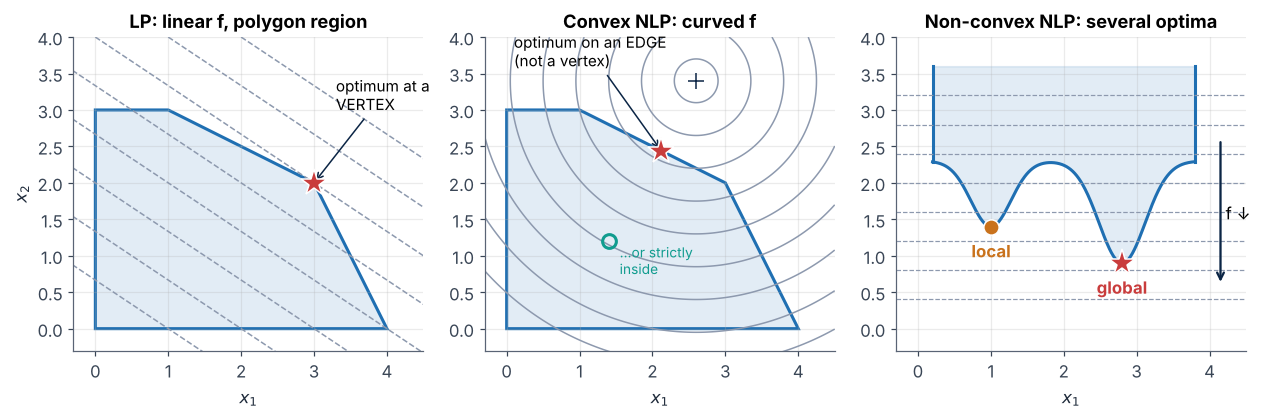

| | **LP** | **NLP** |
|---|---|---|
| Where is the optimum? | always at a **vertex** | at a vertex, on an **edge**, or in the **interior** |
| Is a local optimum global? | always (LP is convex) | **only if the problem is convex** |
| Algorithm | simplex: hop between vertices | gradients and Newton steps on smooth functions |
| Certificate of optimality | duality / reduced costs | **KKT conditions** (+ convexity for a *global* certificate) |

> ⚠️ Without the vertex property, "optimal" needs a new definition. That definition is the **optimality conditions** we build in this lecture.

## 4 ·  Where NLPs live in chemical engineering

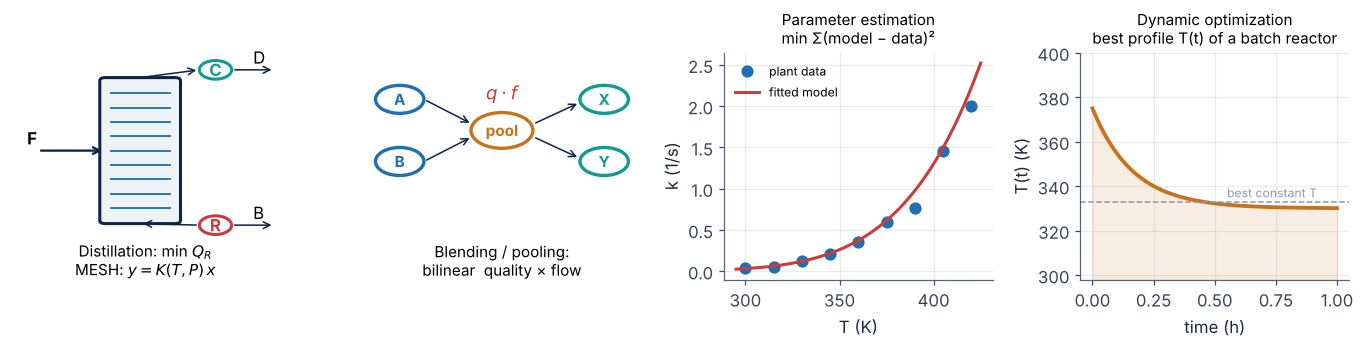

| Application | Decision variables | Why nonlinear? | Typical size |
|---|---|---|---|
| **Distillation energy** (MESH model) | reflux and boil-up, tray $T$, $x$, $y$ | VLE $K(T,P)$, enthalpies | thousands of equations, **only 2 DOF** |
| **Gasoline blending** (60–70 % of refinery revenue) | flows, tank volumes, pool qualities | quality × flow (bilinear) | non-convex, multi-period |
| **Parameter estimation** (LDPE tubular reactor) | ~100 kinetic parameters | Arrhenius kinetics inside ODEs | 2,500 ODEs + 5,000 algebraic eqs |
| **Dynamic optimization** (batch reactors, grade transitions, flight paths) | control profiles $u(t)$ | DAE model | $10^4$–$10^5$ variables after discretization |

>  A column with $N$ trays has **thousands** of MESH equations but **only two** degrees of freedom (e.g., $V_0$ and $L_{N+1}$). Fix those two and the equations determine everything else. The optimizer searches a **2-D space embedded in a huge model**.

## 5 ·  Case study: the Haverly pooling problem

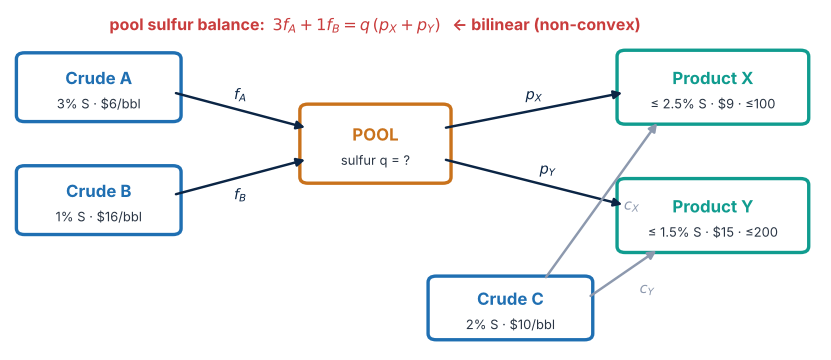

$$\max \; \underbrace{9(p_X + c_X) + 15(p_Y + c_Y)}_{\text{sales}} - \underbrace{6 f_A - 16 f_B - 10(c_X + c_Y)}_{\text{crude cost}}$$

| Constraint | Equation | Type |
|---|---|---|
| pool mass balance | $f_A + f_B = p_X + p_Y$ | linear |
| pool sulfur balance | $3 f_A + f_B = q\,(p_X + p_Y)$ | **bilinear** |
| X sulfur spec | $q\,p_X + 2 c_X \le 2.5\,(p_X + c_X)$ | **bilinear** |
| Y sulfur spec | $q\,p_Y + 2 c_Y \le 1.5\,(p_Y + c_Y)$ | **bilinear** |
| demands | $p_X + c_X \le 100, \quad p_Y + c_Y \le 200$ | linear |

>  Only **one** nonlinear feature (the unknown pool quality $q$ multiplying a flow), yet it makes the problem **non-convex**. We will solve it at the end of the lecture and get **three different answers**.

## ✅ Check Your Understanding 1 — What is an NLP?

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Which of these are NLPs? (a) $\min 3x_1 + 2x_2$ s.t. $x_1 + x_2 \ge 4$ · (b) $\min x_1 + x_2$ s.t. $x_1 x_2 \ge 4$ · (c) $\min\; 2.5\,S^{0.6}$ s.t. $S \ge S_{min}$ · (d) $\min \sum_i (y_i - a\,e^{b t_i})^2$

<details><summary><b> Show answer</b></summary>

(a) is an **LP**. (b), (c) and (d) are **NLPs**: a bilinear constraint, a power-law cost, and a model that is nonlinear in the parameter $b$.

</details>

**Q2.** A flowsheet model has **120 variables** and **115 independent equations**. How many degrees of freedom does the optimizer have?

<details><summary><b> Show answer</b></summary>

$n - m = 120 - 115 =$ **5**. The optimizer only chooses 5 quantities (for example, 2 reflux ratios, 2 temperatures and 1 split fraction); the equations fix the rest.

</details>

**Q3.** Put $\max\; 10\ln x - x^2$ s.t. $x^2 + y \ge 3$ into the standard form $\min f$ s.t. $g \le 0$.

<details><summary><b> Show answer</b></summary>

$\min\; -10\ln x + x^2$ s.t. $3 - x^2 - y \le 0$ (and $x > 0$ for the logarithm).

</details>

**Q4.** Why can't the simplex method solve the pooling problem?

<details><summary><b> Show answer</b></summary>

Simplex assumes linear functions, so that the optimum is at a vertex. The pooling problem has bilinear constraints: its optimum need not be at a vertex, and it can have several local optima.

</details>

# Part B
## Unconstrained Optimization
### *Rolling to the bottom of the valley*

## 6 · Optimality conditions for $\min_x f(x)$

Second-order Taylor expansion around a candidate $x^*$:
$\quad f(x^* + p) \approx f(x^*) + \nabla f(x^*)^\top p + \tfrac12\, p^\top \nabla^2 f(x^*)\, p$

| Condition | Statement | Meaning |
|---|---|---|
| **First-order necessary** | $\nabla f(x^*) = 0$ | no downhill direction ("stationary point") |
| **Second-order necessary** | $p^\top \nabla^2 f(x^*)\, p \ge 0 \;\; \forall p$ | Hessian **positive semi-definite** |
| **Second-order sufficient** | $\nabla f(x^*) = 0$ **and** $p^\top \nabla^2 f(x^*)\, p > 0 \;\; \forall p \ne 0$ | Hessian **positive definite** ⇒ strict local min |

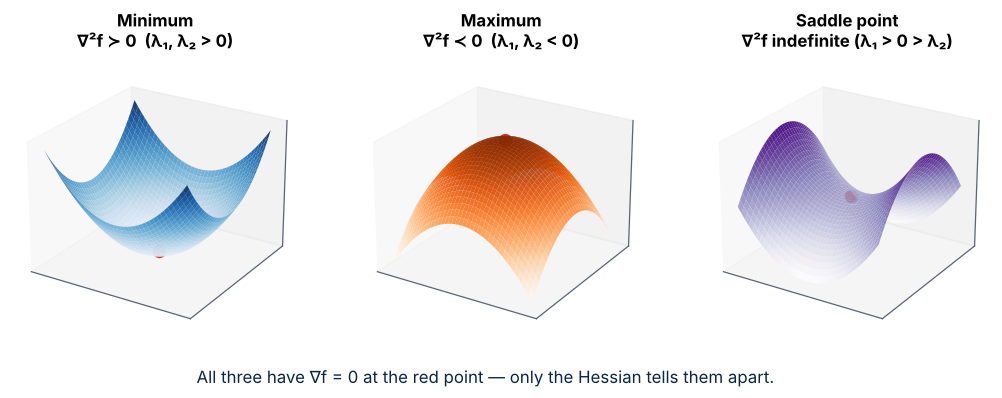

>  **Eigenvalue test:** all eigenvalues of $\nabla^2 f$ positive → minimum · all negative → maximum · mixed signs → saddle · some zero → test is inconclusive.

∇f  = [3*x**2 - 3*y, -3*x + 3*y**2] 
∇²f = [[6*x, -3], [-3, 6*y]] 

(0, 0):  eigenvalues of ∇²f = [-3.  3.]  →  SADDLE
(1, 1):  eigenvalues of ∇²f = [9. 3.]  →  MINIMUM


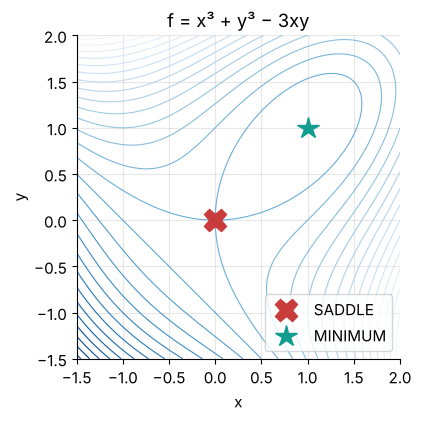

In [ ]:
# 🔬 Find and classify ALL stationary points of f(x, y) = x³ + y³ − 3xy
x, y = sp.symbols("x y", real=True)
f = x**3 + y**3 - 3*x*y
grad = [sp.diff(f, v) for v in (x, y)]
H = sp.hessian(f, (x, y))
print("∇f  =", grad, "\n∇²f =", H.tolist(), "\n")

points = []
for s in sp.solve(grad, (x, y), dict=True):
    if not all(v.is_real for v in s.values()):
        continue                                            # skip complex roots
    ev = np.array([float(e) for e in H.subs(s).eigenvals()])
    kind = "MINIMUM" if ev.min() > 0 else "MAXIMUM" if ev.max() < 0 else "SADDLE"
    points.append((float(s[x]), float(s[y]), kind))
    print(f"({s[x]}, {s[y]}):  eigenvalues of ∇²f = {ev}  →  {kind}")

X, Y = np.meshgrid(np.linspace(-1.5, 2, 300), np.linspace(-1.5, 2, 300))
plt.figure(figsize=(5.2, 4.2))
plt.contour(X, Y, X**3 + Y**3 - 3*X*Y, levels=30, cmap="Blues_r", linewidths=0.8)
for px, py, kind in points:
    plt.plot(px, py, "*" if kind == "MINIMUM" else "X", ms=16, color=TEAL if kind == "MINIMUM" else RED, label=kind)
plt.xlabel("x"); plt.ylabel("y"); plt.legend(loc="lower right"); plt.gca().set_aspect("equal"); plt.title("f = x³ + y³ − 3xy"); plt.show()

## 7 · Newton's method: minimize a local quadratic model

At $x_k$ build the quadratic model $\; m_k(p) = f(x_k) + \nabla f_k^\top p + \tfrac12\, p^\top \nabla^2 f_k\, p\;$ and jump to its stationary point:

$$\boxed{\;\nabla^2 f(x_k)\; p_k = -\nabla f(x_k), \qquad x_{k+1} = x_k + p_k\;}$$

1. choose $x_0$ · 2. compute $\nabla f(x_k)$ and $\nabla^2 f(x_k)$ · 3. solve for $p_k$ and update · 4. stop when $\lVert \nabla f \rVert < \varepsilon$, else repeat

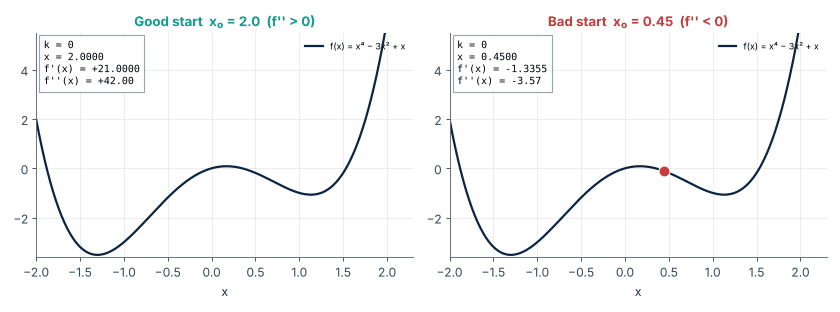

- **Left:** $f'' > 0$, so the model is a bowl and Newton races to the minimum in ~5 steps.
- **Right:** $f'' < 0$, so the model is a **dome** and Newton jumps to its top, converging to a **maximum**!

> ⚠️ Pure Newton finds **stationary points**, not minima. Practical codes make the Hessian positive definite ($\nabla^2 f + \tau I$) and add a **line search** ("damped Newton").

## 8 · How fast? Convergence rates

$$\beta = \lim_{k\to\infty} \frac{\lVert x_{k+1} - x^* \rVert}{\lVert x_k - x^* \rVert^{\,p}}$$

| Rate | Definition | Error sequence (example) | Typical method |
|---|---|---|---|
| **Linear** | $p = 1,\; \beta < 1$ | $10^{-1}, 5{\cdot}10^{-2}, 2.5{\cdot}10^{-2}, \dots$ | steepest descent |
| **Superlinear** | $p = 1,\; \beta \to 0$ | the ratio of errors shrinks each step | quasi-Newton (BFGS) |
| **Quadratic** | $p = 2$ | $10^{-1}, 10^{-2}, 10^{-4}, 10^{-8}, 10^{-16}$ | Newton |

> **Quadratic convergence doubles the number of correct digits at every iteration.** Newton solves a quadratic function in **one** step, because its model is then exact. The price is a Hessian (second derivatives) and a linear solve per iteration.

In [ ]:
#  Race on the Rosenbrock "banana" f = (1 − x₁)² + 100(x₂ − x₁²)²  (minimum at (1, 1))
rosen   = lambda x: (1 - x[0])**2 + 100*(x[1] - x[0]**2)**2
rosen_g = lambda x: np.array([-2*(1 - x[0]) - 400*x[0]*(x[1] - x[0]**2), 200*(x[1] - x[0]**2)])
rosen_H = lambda x: np.array([[2 - 400*(x[1] - 3*x[0]**2), -400*x[0]], [-400*x[0], 200.0]])
x0, xstar = np.array([-1.2, 1.0]), np.array([1.0, 1.0])

def steepest_descent(x, tol=1e-6, kmax=10000):          # exact line search along -∇f
    P = [x]
    while np.linalg.norm(rosen_g(x)) > tol and len(P) < kmax:
        d = -rosen_g(x) / np.linalg.norm(rosen_g(x))
        a = minimize_scalar(lambda a: rosen(x + a*d), bounds=(0, 1), method="bounded", options={"xatol": 1e-10}).x
        x = x + a*d; P.append(x)
    return np.array(P)

def damped_newton(x, tol=1e-10, kmax=100):              # Newton step + backtracking line search
    P = [x]
    while np.linalg.norm(rosen_g(x)) > tol and len(P) < kmax:
        H = rosen_H(x); w = np.linalg.eigvalsh(H)
        if w.min() <= 0: H = H + (1e-3 - w.min())*np.eye(2)    # force H to be positive definite
        p, a = -np.linalg.solve(H, rosen_g(x)), 1.0
        while rosen(x + a*p) > rosen(x) + 1e-4*a*rosen_g(x) @ p: a /= 2
        x = x + a*p; P.append(x)
    return np.array(P)

P_bfgs = [x0]; minimize(rosen, x0, jac=rosen_g, method="BFGS", callback=lambda xk: P_bfgs.append(xk.copy()))
runs = {"steepest descent (linear)": (steepest_descent(x0), GOLD),
        "BFGS (superlinear)":        (np.array(P_bfgs), PURPLE),
        "Newton (quadratic)":        (damped_newton(x0), TEAL)}
for name, (P, c) in runs.items():
    err = np.linalg.norm(P - xstar, axis=1)
    plt.semilogy(err + 1e-17, color=c, lw=2, label=f"{name}: {len(P)-1} iterations")
    print(f"{name:27s} iterations = {len(P)-1:5d}   final error = {err[-1]:.1e}")
plt.xscale("symlog", linthresh=50); plt.xlabel("iteration k"); plt.ylabel("‖xₖ − x*‖"); plt.ylim(1e-16, 10)
plt.legend(fontsize=9); plt.title("Convergence rate is visible as the slope"); plt.show()

NameError: name 'np' is not defined

## 9 · Quasi-Newton methods: BFGS

Can we keep Newton's speed **without** computing $\nabla^2 f$? Build an approximation $B_k \approx \nabla^2 f(x_k)$ from gradient differences:

$$B_{k+1} = B_k + \frac{y\,y^\top}{y^\top s} - \frac{B_k s\, s^\top B_k}{s^\top B_k s}$$
$$s = x_{k+1} - x_k, \qquad y = \nabla f(x_{k+1}) - \nabla f(x_k)$$

(**B**royden, **F**letcher, **G**oldfarb, **S**hanno, 1970)

- **Secant relation** $B_{k+1} s = y$: the new model reproduces the observed change in gradient.
- $B_k$ stays **symmetric positive definite**, so every step is a descent direction.
- **Superlinear** convergence; terminates in at most $n$ steps on a quadratic.
- For $n \lesssim 100$ without second derivatives it is the best general-purpose method; **L-BFGS** stores only a few vectors for large $n$.

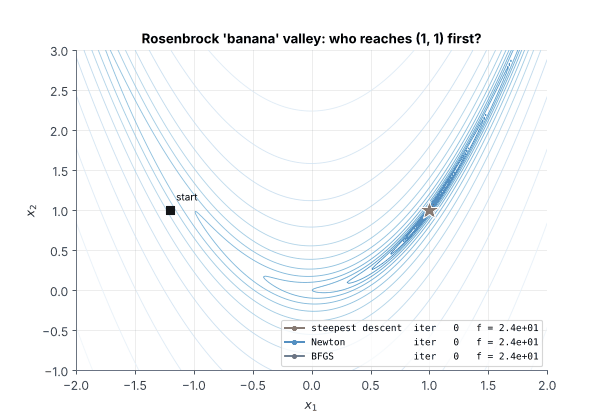

method        iters  f evals  ∇f evals   x*
Nelder-Mead      85      159         0   [1. 1.]
CG               36       78        77   [1. 1.]
BFGS             32       39        39   [1. 1.]
Newton-CG        83      105       105   [1. 1.]


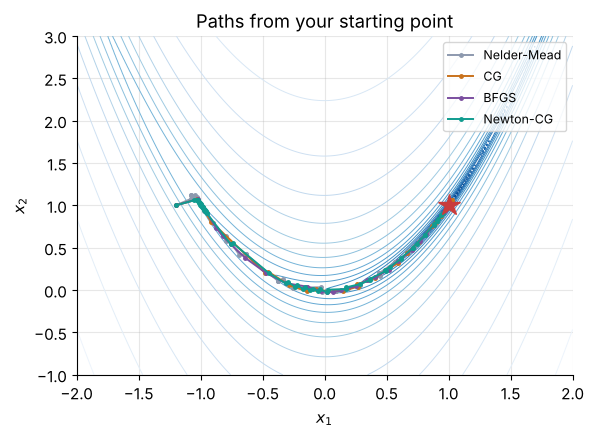

In [ ]:
# 🎚️ Interactive: pick a starting point and compare SciPy's unconstrained methods
methods = ["Nelder-Mead", "CG", "BFGS", "Newton-CG"]
cols = dict(zip(methods, [GRAY, GOLD, PURPLE, TEAL]))

def race(x1_0=-1.2, x2_0=1.0):
    X, Y = np.meshgrid(np.linspace(-2, 2, 250), np.linspace(-1, 3, 250))
    plt.figure(figsize=(6.4, 4.4))
    plt.contour(X, Y, np.log10(rosen([X, Y]) + 1e-2), levels=20, cmap="Blues_r", linewidths=0.7)
    print(f"{'method':12s} {'iters':>6s} {'f evals':>8s} {'∇f evals':>9s}   x*")
    for m in methods:
        path = [np.array([x1_0, x2_0])]
        kw = dict(jac=rosen_g, hess=rosen_H) if m == "Newton-CG" else ({} if m == "Nelder-Mead" else dict(jac=rosen_g))
        r = minimize(rosen, path[0], method=m, callback=lambda xk: path.append(np.copy(xk)), **kw)
        P = np.array(path); plt.plot(P[:, 0], P[:, 1], "-o", ms=2.5, lw=1.4, color=cols[m], label=m)
        print(f"{m:12s} {r.nit:6d} {r.nfev:8d} {r.get('njev', 0):9d}   {r.x.round(4)}")
    plt.plot(1, 1, "*", color=RED, ms=16); plt.xlim(-2, 2); plt.ylim(-1, 3); plt.legend(fontsize=9)
    plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title("Paths from your starting point"); plt.show()

if HAS_WIDGETS:
    interact(race, x1_0=FloatSlider(value=-1.2, min=-2, max=2, step=0.1), x2_0=FloatSlider(value=1.0, min=-1, max=3, step=0.1))
else:
    race()

##  Check Your Understanding 2 — Unconstrained optimization

*Try each question yourself first, then click to reveal the answer.*

**Q1.** At a point $x^*$, $\nabla f(x^*) = 0$ and the Hessian eigenvalues are $4$ and $-1$. What kind of point is it?

<details><summary><b> Show answer</b></summary>

A **saddle point**. The eigenvalues have mixed signs: $f$ curves up along one direction and down along the other.

</details>

**Q2.** How many Newton iterations does it take to minimize $f(x) = \tfrac12 x^\top Q x - b^\top x$ with $Q \succ 0$, from any start?

<details><summary><b> Show answer</b></summary>

**One.** The quadratic model is exact, so $x_1 = x_0 - Q^{-1}(Qx_0 - b) = Q^{-1}b = x^*$.

</details>

**Q3.** The errors of two methods are (A) $0.1, 0.05, 0.025, 0.0125$ and (B) $10^{-1}, 10^{-2}, 10^{-4}, 10^{-8}$. Name the convergence rates.

<details><summary><b> Show answer</b></summary>

(A) **linear** with $\beta = 0.5$. (B) **quadratic**: the exponent doubles every step.

</details>

**Q4.** Your process simulator gives gradients by finite differences, and each simulation takes 2 s. Why is BFGS usually preferred over Newton for 50 variables?

<details><summary><b> Show answer</b></summary>

A finite-difference Hessian costs $O(n^2) \approx 1{,}275$ extra simulations per iteration. BFGS builds curvature from gradients it already has and still converges **superlinearly**.

</details>

**Q5.** **Predict, then run:** Newton's method on $f = x^4 - 3x^2 + x$ from $x_0 = 0.45$. Where does it converge, and is that a minimum?

<details><summary><b> Show answer</b></summary>

To $x \approx 0.170$, where $f''(x) = 12x^2 - 6 < 0$. That is a **local maximum**: Newton solved $f'(x) = 0$ without checking curvature.

</details>

In [ ]:
fp, fpp = lambda x: 4*x**3 - 6*x + 1, lambda x: 12*x**2 - 6
x = 0.45
for k in range(6):
    x = x - fp(x)/fpp(x)
    print(f"k = {k+1}:  x = {x:.6f}   f'(x) = {fp(x):+.2e}   f''(x) = {fpp(x):+.3f}")
print("→", "local MINIMUM" if fpp(x) > 0 else "local MAXIMUM  (f'' < 0)")

k = 1:  x = 0.075910   f'(x) = +5.46e-01   f''(x) = -5.931
k = 2:  x = 0.168020   f'(x) = +1.09e-02   f''(x) = -5.661
k = 3:  x = 0.169937   f'(x) = +7.44e-06   f''(x) = -5.653
k = 4:  x = 0.169938   f'(x) = +3.53e-12   f''(x) = -5.653
k = 5:  x = 0.169938   f'(x) = +0.00e+00   f''(x) = -5.653
k = 6:  x = 0.169938   f'(x) = +0.00e+00   f''(x) = -5.653
→ local MAXIMUM  (f'' < 0)


# Part C
## Equality Constraints
### *Walking on a wire: the method of Lagrange*

## 10 · The geometry of an equality-constrained optimum

$$\min\; x_1 + x_2 \qquad \text{s.t.} \qquad h(x) = x_1^2 + x_2^2 - 1 = 0$$

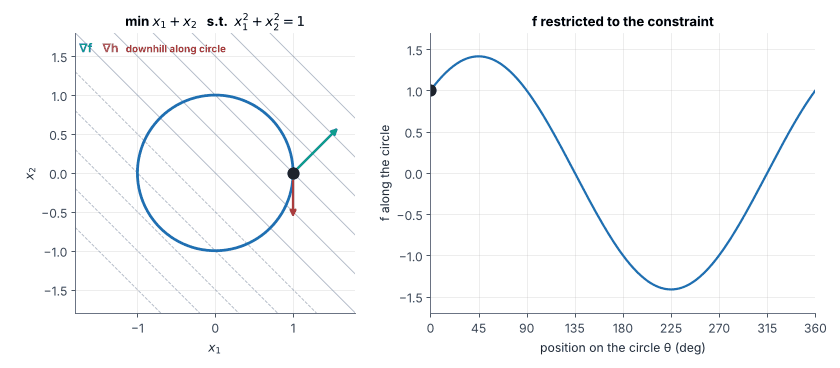

- We can only move **along the circle** (the tangent direction).
- The **red arrow** is the part of $-\nabla f$ along the tangent, i.e., the downhill direction the constraint *allows*.
- At the optimum the red arrow **vanishes**: $\nabla f$ is perpendicular to the circle, so it is **parallel to $\nabla h$**:

$$\nabla f(x^*) + \lambda^* \nabla h(x^*) = 0$$

> 🧠 At a constrained optimum $\nabla f \neq 0$ in general. Instead, the objective's gradient is **balanced** by the constraint gradients.

## 11 · The Lagrangian and the first-order necessary conditions

Fold the constraints into one function with a **Lagrange multiplier** $\lambda_i$ for each $h_i$:

$$L(x, \lambda) = f(x) + \sum_{i=1}^{m} \lambda_i\, h_i(x)$$

**FONC:** if $x^*$ is a local minimum (or maximum), then there exist $\lambda^*$ with

$$\underbrace{\nabla_x L = \nabla f(x^*) + \sum_i \lambda_i^* \nabla h_i(x^*) = 0}_{\text{optimality: } n \text{ equations}} \qquad \underbrace{\nabla_\lambda L = h(x^*) = 0}_{\text{feasibility: } m \text{ equations}}$$

**Circle example:** $L = x_1 + x_2 + \lambda(x_1^2 + x_2^2 - 1)$

| FONC equations | Consequence |
|---|---|
| $\partial L/\partial x_1 = 1 + 2\lambda x_1 = 0$, $\;\partial L/\partial x_2 = 1 + 2\lambda x_2 = 0$ | $x_1 = x_2 = -\tfrac{1}{2\lambda}$ |
| $\partial L/\partial \lambda = x_1^2 + x_2^2 - 1 = 0$ | $\lambda = \pm \tfrac{\sqrt2}{2}$ |

**Two candidates:** $\;x^* = \left(-\tfrac{\sqrt2}{2}, -\tfrac{\sqrt2}{2}\right),\; \lambda = +\tfrac{\sqrt2}{2},\; f = -\sqrt2\;$ and $\;x = \left(+\tfrac{\sqrt2}{2}, +\tfrac{\sqrt2}{2}\right),\; \lambda = -\tfrac{\sqrt2}{2},\; f = +\sqrt2$

> ❓ Both points satisfy the FONC. **Which one is the minimum?** We need curvature, and curvature only *along the constraint* matters.

## 12 · Second-order conditions (on the tangent space)

Use the **Hessian of the Lagrangian** $\;\nabla_{xx}^2 L = \nabla^2 f + \sum_i \lambda_i \nabla^2 h_i\;$ and test only **feasible directions** $y$ in the tangent space $\;\nabla h(x^*)^\top y = 0$:

| Condition | Test |
|---|---|
| **Necessary:** if $x^*$ is a local min then | $y^\top \nabla_{xx}^2 L(x^*, \lambda^*)\, y \ge 0$ for all tangent $y$ (PSD on the tangent space) |
| **Sufficient:** $x^*$ is a strict local min if | $y^\top \nabla_{xx}^2 L(x^*, \lambda^*)\, y > 0$ for all tangent $y \ne 0$ (PD on the tangent space) |

**Circle example:** $\nabla^2 f = 0$ (a linear objective has no curvature!), but $\nabla_{xx}^2 L = 2\lambda I$:
- at $(-0.707, -0.707)$: $\lambda = +0.707 \Rightarrow y^\top(1.414\, I)y > 0$ ⇒ **minimum** ✅
- at $(+0.707, +0.707)$: $\lambda = -0.707 \Rightarrow y^\top(-1.414\, I)y < 0$ ⇒ **maximum**

> 🧠 The curvature that makes a constrained minimum can come entirely from the **constraint**, weighted by its multiplier.

In [ ]:
# 🔬 Solve the FONC symbolically, then classify with the tangent-space (reduced) Hessian
x1, x2, lam = sp.symbols("x1 x2 lambda", real=True)
f, h = x1 + x2, x1**2 + x2**2 - 1
L = f + lam*h
sols = sp.solve([sp.diff(L, x1), sp.diff(L, x2), h], [x1, x2, lam], dict=True)

HL = sp.hessian(L, (x1, x2))                     # ∇²ₓₓ L
Jh = sp.Matrix([h]).jacobian([x1, x2])           # ∇hᵀ (1 × 2)
for s in sols:
    Z = Jh.subs(s).nullspace()[0]                # basis of the tangent space {y : ∇hᵀy = 0}
    curv = float((Z.T * HL.subs(s) * Z)[0])
    print(f"x = ({float(s[x1]):+.3f}, {float(s[x2]):+.3f})  λ = {float(s[lam]):+.3f}  "
          f"f = {float(f.subs(s)):+.3f}  yᵀ∇²L y = {curv:+.3f}  →  {'MINIMUM' if curv > 0 else 'MAXIMUM'}")

x = (+0.707, +0.707)  λ = -0.707  f = +1.414  yᵀ∇²L y = -2.828  →  MAXIMUM
x = (-0.707, -0.707)  λ = +0.707  f = -1.414  yᵀ∇²L y = +2.828  →  MINIMUM


## 13 · 🛠️ Optimal storage-tank design (and what $\lambda$ means)

Store volume $V$ in a closed cylinder using the least steel (surface area):

$$\min_{r,\,h}\; A = 2\pi r^2 + 2\pi r h \qquad \text{s.t.}\qquad \pi r^2 h = V$$

**Lagrange:** $\;2\pi(2r + h) + 2\pi\lambda r h = 0, \quad 2\pi r + \lambda\pi r^2 = 0 \;\Rightarrow\; \lambda^* = -\dfrac{2}{r^*}, \quad \boxed{h^* = 2r^*}$

- The optimal tank is exactly as **tall as it is wide** ($h = D$).
- **Meaning of $\lambda$:** $\dfrac{dA^*}{dV} = -\lambda^* = \dfrac{2}{r^*}$, the **extra steel (m²) needed per extra m³ of capacity**: a marginal cost.
- With different costs for the shell ($c_s$) and the heads ($c_h$), the same analysis gives $h/D = c_h/c_s$. Thicker, more expensive heads give taller tanks.

In [ ]:
# 🔬 Tank design: solve the Lagrange conditions, then check λ against a finite difference
r, hh, V = sp.symbols("r h V", positive=True); lam = sp.symbols("lambda", real=True)
A = 2*sp.pi*r**2 + 2*sp.pi*r*hh
L = A + lam*(sp.pi*r**2*hh - V)
lam_r = sp.solve(sp.diff(L, hh), lam)[0]                        # ∂L/∂h = 0  →  λ in terms of r
h_r   = sp.solve(sp.diff(L, r).subs(lam, lam_r), hh)[0]         # ∂L/∂r = 0  →  h in terms of r
r_opt = sp.solve((sp.pi*r**2*hh - V).subs(hh, h_r), r)[0]       # ∂L/∂λ = 0  →  r in terms of V
sol = {r: r_opt, hh: h_r.subs(r, r_opt), lam: lam_r.subs(r, r_opt)}
print("from ∂L/∂h = 0:  λ =", lam_r, "    from ∂L/∂r = 0:  h =", h_r, "    from h(x) = 0:  r* =", r_opt)

A_star = sp.lambdify(V, A.subs(sol))                         # optimal area as a function of V
for Vn in [100.0]:
    rn, hn, ln = (float(sol[k].subs(V, Vn)) for k in (r, hh, lam))
    print(f"\nV = {Vn:.0f} m³:  r = {rn:.3f} m,  h = {hn:.3f} m  (h/r = {hn/rn:.2f}),  A = {A_star(Vn):.2f} m²")
    print(f"  −λ*                    = {-ln:.4f} m² per m³")
    print(f"  [A*(V+1) − A*(V)] / 1  = {A_star(Vn + 1) - A_star(Vn):.4f} m² per m³   ← matches the multiplier")

from ∂L/∂h = 0:  λ = -2/r     from ∂L/∂r = 0:  h = 2*r     from h(x) = 0:  r* = 2**(2/3)*V**(1/3)/(2*pi**(1/3))

V = 100 m³:  r = 2.515 m,  h = 5.031 m  (h/r = 2.00),  A = 119.27 m²
  −λ*                    = 0.7951 m² per m³
  [A*(V+1) − A*(V)] / 1  = 0.7938 m² per m³   ← matches the multiplier


## ✅ Check Your Understanding 3 — Lagrange multipliers

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Solve $\min\; x_1^2 + x_2^2$ s.t. $x_1 + x_2 = 4$ with a Lagrangian. What are $x^*$, $\lambda^*$ and $f^*$?

<details><summary><b>👉 Show answer</b></summary>

$2x_1 + \lambda = 0,\; 2x_2 + \lambda = 0 \Rightarrow x_1 = x_2 = 2$, $\lambda^* = -4$, $f^* = 8$.

</details>

**Q2.** In Q1, the right-hand side changes from 4 to 4.1. Estimate the new $f^*$ using only $\lambda^*$.

<details><summary><b>👉 Show answer</b></summary>

$\Delta f^* \approx -\lambda^*\,\Delta b = 4 \times 0.1 = 0.4$, so $f^* \approx 8.4$. The exact value is $2(2.05)^2 = 8.405$.

</details>

**Q3.** At a constrained minimum, must $\nabla f(x^*) = 0$?

<details><summary><b>👉 Show answer</b></summary>

**No.** $\nabla f(x^*)$ must be a combination of the constraint gradients: $\nabla f = -\sum_i \lambda_i \nabla h_i$. In the circle example $\nabla f = (1, 1)$ everywhere.

</details>

**Q4.** A problem has $n = 5$ variables and $m = 2$ equality constraints. How many equations and unknowns are in the FONC system?

<details><summary><b>👉 Show answer</b></summary>

$n + m =$ **7 equations** in **7 unknowns** ($x_1, \dots, x_5, \lambda_1, \lambda_2$). The system is usually nonlinear, so it is solved with Newton's method (this is the idea behind SQP in Module 3B).

</details>

# Part D
## Inequality Constraints & the KKT Conditions
### *A ball rolling downhill, pinned against a fence*

## 14 · Active and inactive constraints

At a point $x^*$, an inequality $g_j(x) \le 0$ is

- **active** if $g_j(x^*) = 0$: we are pressed against it;
- **inactive** if $g_j(x^*) < 0$: there is room to spare.

The **active set** is $I(x^*) = \{\, j : g_j(x^*) = 0 \,\}$.

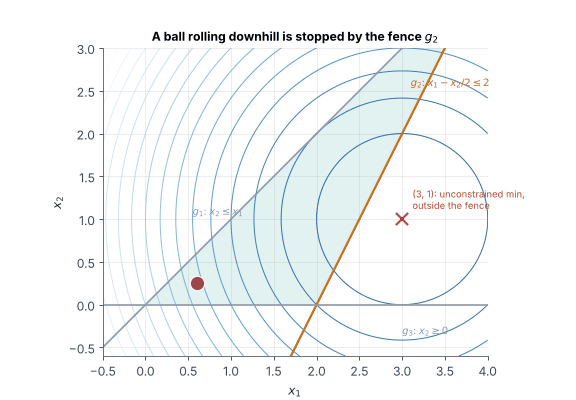

- The ball rests either at the valley floor (**nothing active**) or **pinned against a fence** (**active**).
- At rest, the **downhill pull** $-\nabla f$ is balanced by the **fence's push** $-\mu_j \nabla g_j$.
- A fence can only **push** and never **pull** ⇒ $\mu_j \ge 0$.

>  An inactive constraint could be deleted without changing the local solution. **Only active constraints matter.**

## 15 · The Karush–Kuhn–Tucker (KKT) conditions

For $\;\min f(x)$ s.t. $h_i(x) = 0,\; g_j(x) \le 0$, form $\;L(x, \lambda, \mu) = f(x) + \sum_i \lambda_i h_i(x) + \sum_j \mu_j g_j(x)$.

If $x^*$ is a local minimum (and a **constraint qualification** holds), there exist $\lambda^*, \mu^*$ such that:

| | Condition | Physical meaning |
|---|---|---|
| **1 · Stationarity** | $\nabla f(x^*) + \sum_i \lambda_i^* \nabla h_i(x^*) + \sum_j \mu_j^* \nabla g_j(x^*) = 0$ | **force balance** |
| **2 · Primal feasibility** | $h_i(x^*) = 0, \quad g_j(x^*) \le 0$ | we are inside the fences |
| **3 · Dual feasibility** | $\mu_j^* \ge 0$ | fences only **push** |
| **4 · Complementary slackness** | $\mu_j^*\, g_j(x^*) = 0$ | either $g_j = 0$ (active) **or** $\mu_j = 0$ (no force) |

- $\lambda_i$ (equalities) can have **any sign**; $\mu_j$ (inequalities, for a **min** with $g \le 0$) must be **≥ 0**.
- Complementary slackness is the algebraic form of "only active constraints push".

>  **KKT = Lagrange + force balance + "fences can only push".** These are the conditions every NLP solver checks to declare "optimal".

## 16 · A one-variable KKT example: $\min\, \pm x^2$ on $-a \le x \le a$

$L(x, u) = \pm x^2 + u_1 (x - a) + u_2(-a - x)$, with stationarity $\pm 2x + u_1 - u_2 = 0$ and $u_1(x - a) = 0,\; u_2(-a - x) = 0,\; u_1, u_2 \ge 0$

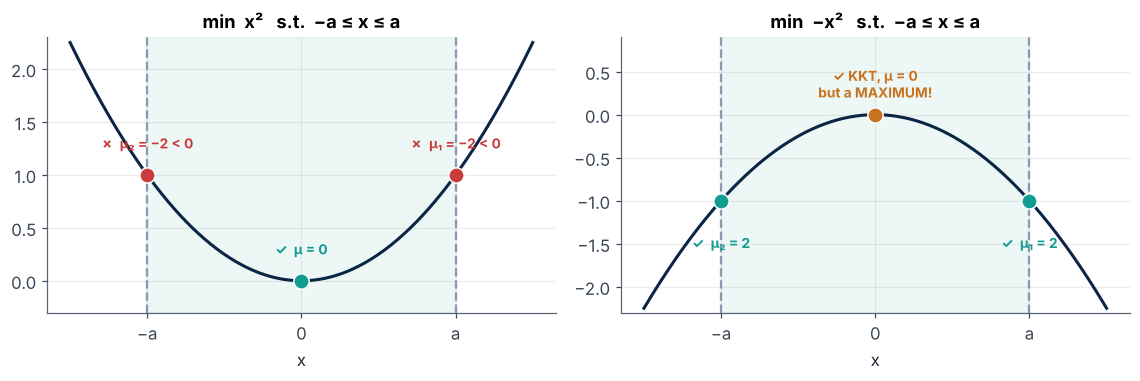

| Case (active set) | $\min\; x^2$ | $\min\; -x^2$ |
|---|---|---|
| upper bound active ($x = a$, $u_2 = 0$) | $u_1 = -2a < 0$ ✗ | $u_1 = 2a \ge 0$ ✓ |
| lower bound active ($x = -a$, $u_1 = 0$) | $u_2 = -2a < 0$ ✗ | $u_2 = 2a \ge 0$ ✓ |
| no bound active ($u_1 = u_2 = 0$) | $x = 0$ ✓ **(the minimum)** | $x = 0$ ✓ **but it is a maximum!** |

> ⚠️ For $\min\,-x^2$, three points satisfy KKT and one of them ($x = 0$) is the **worst** feasible point. **KKT is necessary, not sufficient**, unless the problem is convex (Part E).

In [ ]:
# 🔬 Enumerate the three active-set cases with SymPy and test the KKT sign conditions
a = 1
x, u1, u2 = sp.symbols("x u1 u2", real=True)
for sgn, name in [(1, "min  x²"), (-1, "min −x²")]:
    L = sgn*x**2 + u1*(x - a) + u2*(-a - x)
    print(f"── {name} on [−{a}, {a}] ──")
    cases = {"upper bound active": [x - a, u2], "lower bound active": [-a - x, u1], "no bound active   ": [u1, u2]}
    for cname, eqs in cases.items():
        s = sp.solve([sp.diff(L, x)] + eqs, [x, u1, u2], dict=True)[0]
        ok = (s[u1] >= 0) and (s[u2] >= 0) and (-a <= s[x] <= a)
        print(f"  {cname}: x = {str(s[x]):>2}, u1 = {str(s[u1]):>2}, u2 = {str(s[u2]):>2}, f = {str(sgn*s[x]**2):>2}   →  {'KKT ✓' if ok else 'not KKT ✗'}")

── min  x² on [−1, 1] ──
  upper bound active: x =  1, u1 = -2, u2 =  0, f =  1   →  not KKT ✗
  lower bound active: x = -1, u1 =  0, u2 = -2, f =  1   →  not KKT ✗
  no bound active   : x =  0, u1 =  0, u2 =  0, f =  0   →  KKT ✓
── min −x² on [−1, 1] ──
  upper bound active: x =  1, u1 =  2, u2 =  0, f = -1   →  KKT ✓
  lower bound active: x = -1, u1 =  0, u2 =  2, f = -1   →  KKT ✓
  no bound active   : x =  0, u1 =  0, u2 =  0, f =  0   →  KKT ✓


## 17 · KKT multipliers are shadow prices

Also called **Lagrange multipliers**, **dual variables** or **shadow prices**. For a constraint written as $g_j(x) \le b_j$:

$$\mu_j^* = -\frac{\partial f^*}{\partial b_j} \qquad \text{(rate of improvement of the optimum per unit relaxation)}$$

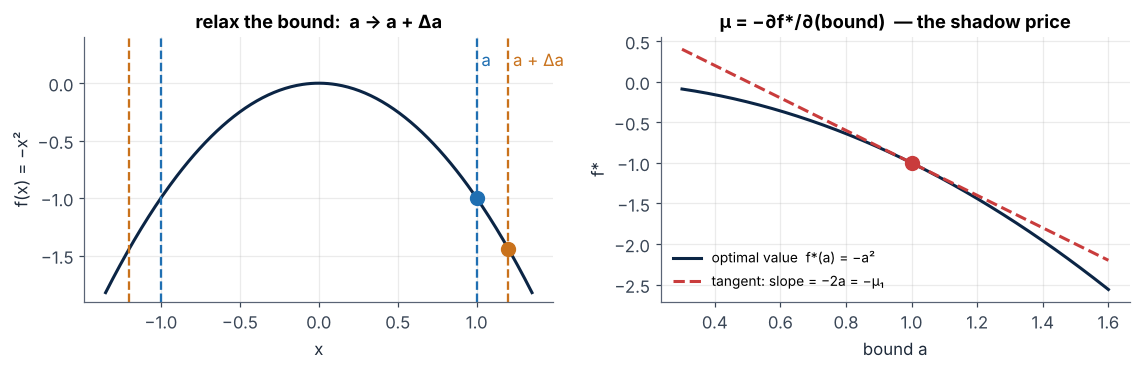

For $\min -x^2$ on $[-a, a]$: $\;f^*(a) = -a^2 \Rightarrow \dfrac{df^*}{da} = -2a = -\mu_1$ ✓

🛠️ **In a plant:** if the steam-header constraint has $\mu = 35$ \$/h per (t/h), then one extra t/h of steam saves about 35 \$/h. Multipliers tell you **which bottleneck to debottleneck first**, and an inactive constraint ($\mu = 0$) is worth nothing to relax.

In [ ]:
# 🔬 Check μ₂ = 0.4 of the worked example (Part E) by relaxing g₂: x₁ − x₂/2 ≤ 2 + δ
fq = lambda x: 0.5*(x[0]**2 + x[1]**2) - 3*x[0] - x[1]
def f_star(delta):
    cons = [{"type": "ineq", "fun": lambda x: x[0] - x[1]},                    # g1: −x1 + x2 ≤ 0
            {"type": "ineq", "fun": lambda x: 2 + delta - x[0] + 0.5*x[1]},    # g2: x1 − x2/2 ≤ 2 + δ
            {"type": "ineq", "fun": lambda x: x[1]}]                           # g3: −x2 ≤ 0
    return minimize(fq, [0.5, 0.2], method="SLSQP", constraints=cons, options={"ftol": 1e-14}).fun

print(f"f*(0) = {f_star(0):.6f}")
for d in [0.1, 0.01, 0.001]:
    print(f"δ = {d:<6}:  Δf*/δ = {(f_star(d) - f_star(0))/d:+.4f}     (theory: −μ₂ = −0.4)")

f*(0) = -4.900000
δ = 0.1   :  Δf*/δ = -0.3600     (theory: −μ₂ = −0.4)
δ = 0.01  :  Δf*/δ = -0.3960     (theory: −μ₂ = −0.4)
δ = 0.001 :  Δf*/δ = -0.3996     (theory: −μ₂ = −0.4)


## 18 · Constraint qualification: when KKT can fail

KKT is guaranteed at a local optimum **only if a constraint qualification (CQ) holds**.

- **LICQ** (Linear Independence CQ): the gradients of the **active** inequalities and of all equalities, $[\nabla g_A(x^*)\;\; \nabla h(x^*)]$, are **linearly independent**. Under LICQ the multipliers exist and are **unique**.
- Other CQs: all constraints **linear** (always fine) · **Slater** (convex problem with a strictly feasible point).

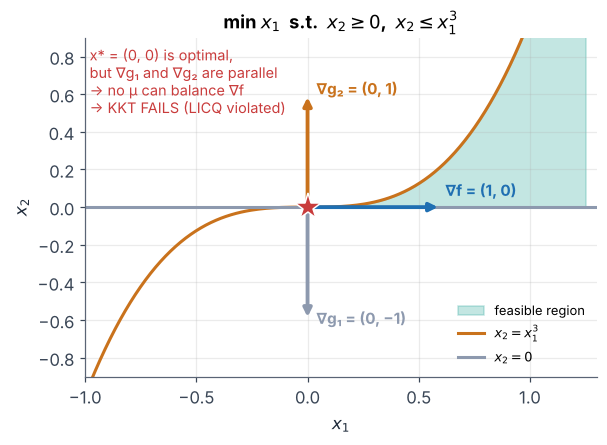

**Example:** $\min\, x_1$ s.t. $x_2 \ge 0$, $x_2 \le x_1^3$. The optimum is $(0, 0)$, but stationarity requires
$\begin{bmatrix}1\\0\end{bmatrix} + u_1\begin{bmatrix}0\\-1\end{bmatrix} + u_2\begin{bmatrix}-3x_1^2\\1\end{bmatrix} = 0$, and the first row reads $1 = 0$: **impossible**.

> ⚠️ Solvers declare optimality by checking the KKT residual. Where the CQ fails they may stall or report failure **even at the true optimum**. Avoid cusps and duplicated or redundant equality constraints in your models.

##  Check Your Understanding 4 — KKT conditions

*Try each question yourself first, then click to reveal the answer.*

**Q1.** A solver reports $g_1 = -0.3,\; g_2 = 0,\; \mu_1 = 0.2,\; \mu_2 = 1.5$ (and stationarity holds). Is this a KKT point?

<details><summary><b> Show answer</b></summary>

**No.** Complementary slackness fails for $g_1$: it is inactive ($g_1 < 0$) but has $\mu_1 \ne 0$, so $\mu_1 g_1 = -0.06 \ne 0$.

</details>

**Q2.** For a minimization with $g \le 0$, the active-set equations give $\mu_j = -0.5$. What does the negative sign tell you?

<details><summary><b> Show answer</b></summary>

The "fence is pulling": moving **away** from constraint $j$ into the feasible interior would **decrease** $f$. The constraint should **not** be active, so drop it from the active set.

</details>

**Q3.** Minimizing operating cost subject to purity ≥ 99.0 % gives $\mu = 120$ \$/h per percent purity. Estimate the saving if the spec is relaxed to 98.9 %.

<details><summary><b> Show answer</b></summary>

$\Delta \text{cost} \approx -\mu\, \Delta b = -120 \times 0.1 = $ **−12 \$/h** (a saving of about 12 \$/h). This is the value of a looser spec, which is useful when negotiating with the customer.

</details>

**Q4.** At $x^*$ two active constraints have gradients $(1, 2)$ and $(2, 4)$. Does LICQ hold?

<details><summary><b> Show answer</b></summary>

**No.** $(2, 4) = 2 \times (1, 2)$, so the gradients are linearly dependent and the multipliers are not unique (and may not exist).

</details>

# Part E
## Convexity & Solving the KKT Conditions
### *When is a KKT point THE answer?*

## 19 · Convexity turns "necessary" into "sufficient and global"

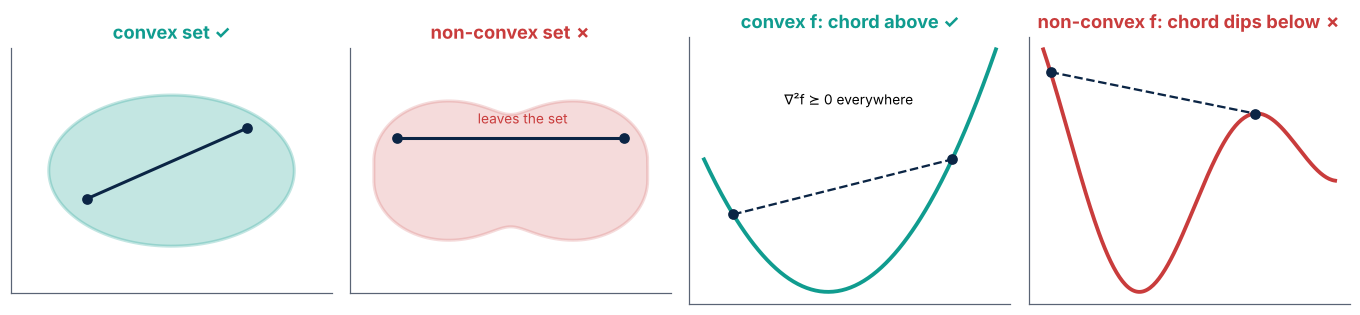

> 🧠 **Sufficient condition for a global optimum.** If $f$ is **convex**, every $g_j$ is **convex**, and every $h_i$ is **linear**, then the feasible region is convex and
> **any KKT point is a global minimum.** No second-order check is needed.

| Building block | Convex? | 🛠️ Where it appears |
|---|---|---|
| $a^\top x + b$, $\;x^2$, $\;e^{x}$, $\;-\ln x$, $\;\lVert x \rVert$ | ✅ convex | costs, least squares, entropy terms |
| $\ln x$, $\;\sqrt{x}$, $\;x^{0.6}$ | concave | **economies of scale**: minimizing concave cost is non-convex! |
| $x \cdot y$ (bilinear), $\;\sin x$, $\;x^3$ | neither | pooling, energy balances, oscillating models |
| nonlinear **equality** $h(x) = 0$ | ✗ (almost never convex) | e.g., the circle $x_1^2 + x_2^2 = 1$ |

⚠️ If these conditions fail there is **no guarantee** that a local optimum is global, although it still might be.

## 20 · The active-set procedure for finding KKT points

Complementarity ($\mu_j g_j = 0$ with $\mu_j \ge 0$) is an **either/or** condition, so KKT is **not** just a system of equations: there are up to $2^p$ active-set combinations. The **active-set strategy** guesses the active set and repairs the guess:

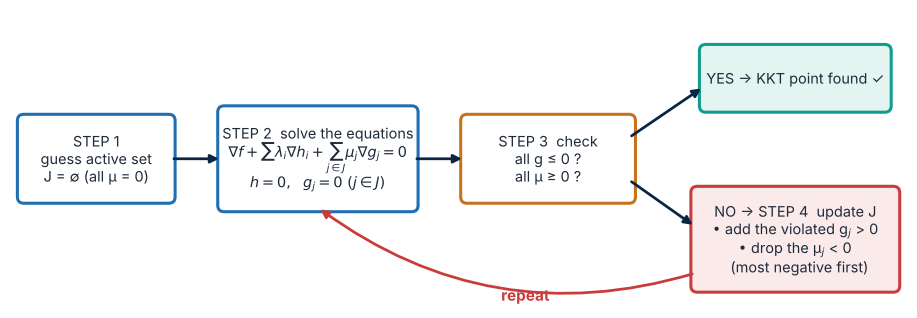

- **Drop** the constraint whose $\mu_j < 0$ has the largest magnitude, since $\mu_j = -\partial f/\partial g_j < 0$ means leaving it lowers $f$.
- **Add** violated constraints ($g_j > 0$); at most $n$ constraints can be active at once.

## 21 · Worked example: the active-set procedure step by step

$$\min\; f = \tfrac12(x_1^2 + x_2^2) - 3x_1 - x_2$$
$$\text{s.t.} \quad g_1 = -x_1 + x_2 \le 0, \qquad g_2 = x_1 - \tfrac12 x_2 - 2 \le 0, \qquad g_3 = -x_2 \le 0$$

$\nabla f = \begin{bmatrix} x_1 - 3 \\ x_2 - 1 \end{bmatrix}, \quad \nabla g_1 = \begin{bmatrix} -1 \\ 1 \end{bmatrix}, \quad \nabla g_2 = \begin{bmatrix} 1 \\ -0.5 \end{bmatrix}, \quad \nabla g_3 = \begin{bmatrix} 0 \\ -1 \end{bmatrix}$

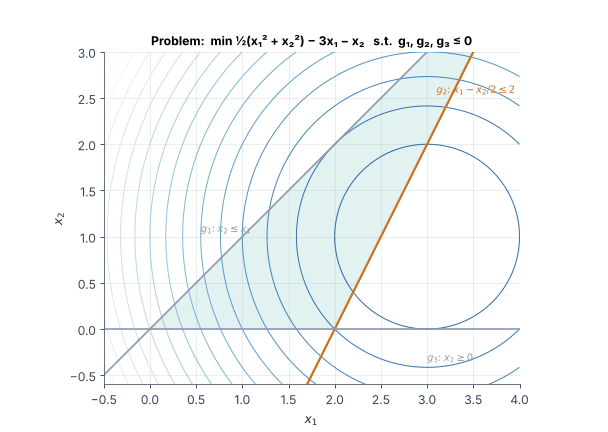

| Iter. | Active set $J$ | Solve | Result | Check |
|---|---|---|---|---|
| 1 | $\varnothing$ | $\nabla f = 0$ | $x = (3, 1)$ | $g_2 = +0.5$ ✗ add $g_2$ |
| 2 | $\{2\}$ | $\nabla f + \mu_2 \nabla g_2 = 0$, $g_2 = 0$ | $x = (2.6, 1.2)$, $\mu_2 = 0.4$ | all $g \le 0$, $\mu \ge 0$ ✓ |

**Verification:** $\begin{bmatrix}-0.4\\0.2\end{bmatrix} + 0.4\begin{bmatrix}1\\-0.5\end{bmatrix} = \begin{bmatrix}0\\0\end{bmatrix}$ ✓. The Hessian $\nabla^2 f = I \succ 0$ and the constraints are linear, so $x^* = (2.6, 1.2)$ with $f^* = -4.9$ is the **unique global** optimum.

In [ ]:
# 🔬 Brute force: try ALL 2³ = 8 active sets.  For a QP each guess is just a LINEAR system.
H = np.eye(2); c = np.array([-3.0, -1.0])                        # f = ½xᵀHx + cᵀx
A = np.array([[-1.0, 1.0], [1.0, -0.5], [0.0, -1.0]]); b = np.array([0.0, 2.0, 0.0])   # A x ≤ b

print(f"{'active set J':14s} {'x':>18s} {'μ_J':>16s}  {'max g':>7s}  {'f':>7s}   verdict")
for k in range(4):
    for J in itertools.combinations(range(3), k):
        J = list(J); AJ = A[J]
        K = np.block([[H, AJ.T], [AJ, np.zeros((k, k))]])            # KKT matrix
        if np.linalg.matrix_rank(K) < K.shape[0]:
            print(f"{str([j+1 for j in J]):14s} {'— more active constraints than the geometry allows —':>58s}"); continue
        sol = np.linalg.solve(K, np.r_[-c, b[J]]); x, mu = sol[:2], sol[2:]
        feas, dual = (A @ x - b).max() <= 1e-9, (mu >= -1e-9).all()
        verdict = "✅ KKT POINT" if feas and dual else ("✗ infeasible" if not feas else "✗ μ < 0")
        print(f"{str([j+1 for j in J]):14s} {str(x.round(3)):>18s} {str(mu.round(3)):>16s}  {(A@x-b).max():+7.2f}  {0.5*x@x + c@x:7.3f}   {verdict}")

active set J                    x              μ_J    max g        f   verdict
[]                        [3. 1.]               []    +0.50   -5.000   ✗ infeasible
[1]                       [2. 2.]            [-1.]    +0.00   -4.000   ✗ μ < 0
[2]                     [2.6 1.2]            [0.4]    +0.00   -4.900   ✅ KKT POINT
[3]                       [3. 0.]            [-1.]    +1.00   -4.500   ✗ infeasible
[1, 2]                    [4. 4.]        [-7. -8.]    +0.00    0.000   ✗ μ < 0
[1, 3]                    [0. 0.]        [-3. -4.]    +0.00    0.000   ✗ μ < 0
[2, 3]                    [2. 0.]      [ 1.  -1.5]    +0.00   -4.000   ✗ μ < 0
[1, 2, 3]            — more active constraints than the geometry allows —


## 22 · 🛠️ The non-convex trap: back to the pooling problem

The pooling problem has **bilinear** constraints, so it is **not convex**: KKT points need not be global. Let's run a local NLP solver (SLSQP) from **60 random starting points**.

profit =    0.0 $/day   found from  3 of 60 starts
profit =  100.0 $/day   found from 10 of 60 starts
profit =  400.0 $/day   found from 47 of 60 starts

best plan: fA = 0, fB = 100, cX = 0, cY = 100, pX = 0, pY = 100, q = 1.00 %S


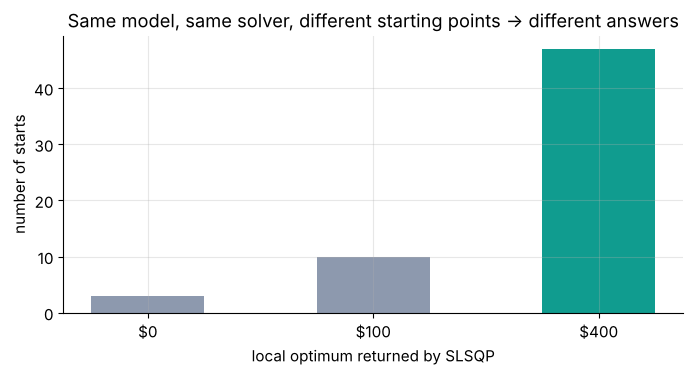

In [ ]:
# 🔬 Haverly pooling problem: x = [fA, fB, cX, cY, pX, pY, q]
profit = lambda x: 9*(x[4] + x[2]) + 15*(x[5] + x[3]) - 6*x[0] - 16*x[1] - 10*(x[2] + x[3])
cons = [{"type": "eq",   "fun": lambda x: x[0] + x[1] - x[4] - x[5]},                    # pool mass
        {"type": "eq",   "fun": lambda x: 3*x[0] + x[1] - x[6]*(x[4] + x[5])},           # pool sulfur (bilinear)
        {"type": "ineq", "fun": lambda x: 100 - x[4] - x[2]},                            # demand X
        {"type": "ineq", "fun": lambda x: 200 - x[5] - x[3]},                            # demand Y
        {"type": "ineq", "fun": lambda x: 2.5*(x[4] + x[2]) - x[6]*x[4] - 2*x[2]},      # X spec (bilinear)
        {"type": "ineq", "fun": lambda x: 1.5*(x[5] + x[3]) - x[6]*x[5] - 2*x[3]}]      # Y spec (bilinear)
bounds = [(0, 300)]*6 + [(1, 3)]

found = []
for s in range(60):
    x0 = np.r_[rng.uniform(0, 200, 6), rng.uniform(1, 3)]
    r = minimize(lambda x: -profit(x), x0, method="SLSQP", bounds=bounds, constraints=cons, options={"maxiter": 500, "ftol": 1e-9})
    # warm restart from the returned point: SLSQP sometimes stops early at degenerate points
    r = minimize(lambda x: -profit(x), r.x, method="SLSQP", bounds=bounds, constraints=cons, options={"maxiter": 500, "ftol": 1e-9})
    if r.success: found.append((round(-r.fun, 1) + 0.0, r.x))

vals, counts = np.unique([v for v, _ in found], return_counts=True)
for v, n in zip(vals, counts):
    print(f"profit = {v:6.1f} $/day   found from {n:2d} of {len(found)} starts")
best = max(found, key=lambda t: t[0])[1]
print("\nbest plan: fA = %.0f, fB = %.0f, cX = %.0f, cY = %.0f, pX = %.0f, pY = %.0f, q = %.2f %%S" % tuple(best))
plt.bar([f"${v:.0f}" for v in vals], counts, color=[GRAY if v < vals.max() else TEAL for v in vals], width=0.5)
plt.ylabel("number of starts"); plt.xlabel("local optimum returned by SLSQP")
plt.title("Same model, same solver, different starting points → different answers"); plt.show()

> 🧠 Every run ended with *"Optimization terminated successfully"*: each answer satisfies the KKT conditions **locally**. Yet a plant running the \$100 plan loses **\$300 per day** compared with the \$400 plan.
>
> **Defenses:** good initial guesses from engineering insight · **multistart** (cheap, parallel, but no guarantee) · **global solvers** (BARON, Couenne, SCIP), which use convex relaxations of the bilinear terms (later in the course).

##  Check Your Understanding 5 — Convexity & active sets

*Try each question yourself first, then click to reveal the answer.*

**Q1.** For $\min\, x_1^2 + x_2^2$ s.t. $x_1 + x_2 \ge 2$, find the KKT point. Is it global?

<details><summary><b> Show answer</b></summary>

$g = 2 - x_1 - x_2 \le 0$ is active: $2x_i - \mu = 0 \Rightarrow x = (1, 1)$, $\mu = 2 \ge 0$. The objective is convex and the constraint linear, so it is the **global** minimum ($f^* = 2$).

</details>

**Q2.** Is the feasible set $\{x : x_1^2 + x_2^2 = 1\}$ convex? What about $\{x : x_1^2 + x_2^2 \le 1\}$?

<details><summary><b> Show answer</b></summary>

The **circle** is not convex: the chord between two points on it passes through the inside. The **disk** is convex ($g$ is a convex function and the constraint is $\le$).

</details>

**Q3.** In the active-set procedure, $J = \{1, 2\}$ gives $\mu_1 = -0.7,\; \mu_2 = 0.3$ and all $g \le 0$. What is the next step?

<details><summary><b> Show answer</b></summary>

**Drop constraint 1** (negative multiplier) and re-solve with $J = \{2\}$.

</details>

**Q4.** SLSQP returns a profit of \$100 for the pooling problem with `success = True`. Is it optimal?

<details><summary><b> Show answer</b></summary>

Only **locally**. `success` means the KKT conditions hold at that point. The problem is non-convex, so the \$400 global optimum exists elsewhere.

</details>

**Q5.** **Predict, then run:** for Q1, will SLSQP find the same point from 5 very different starting points?

<details><summary><b> Show answer</b></summary>

**Yes.** For a convex problem every KKT point is the global minimum (here it is also unique), so every start returns $(1, 1)$.

</details>

In [ ]:
for x0 in rng.uniform(-10, 10, (5, 2)):
    r = minimize(lambda x: x[0]**2 + x[1]**2, x0, method="SLSQP",
                 constraints=[{"type": "ineq", "fun": lambda x: x[0] + x[1] - 2}])
    print(f"start {x0.round(2)!s:>16s}  →  x* = {r.x.round(4)},  f* = {r.fun:.4f}")

start      [2.81 5.79]  →  x* = [1. 1.],  f* = 2.0000
start    [-2.54 -2.38]  →  x* = [1. 1.],  f* = 2.0000
start    [-9.02 -6.03]  →  x* = [1. 1.],  f* = 2.0000
start    [ 6.52 -3.84]  →  x* = [0.9999 1.0001],  f* = 2.0000
start    [ 8.32 -7.86]  →  x* = [1. 1.],  f* = 2.0000


## 23 · Summary & what's next

| Idea | Remember |
|---|---|
| NLP | nonlinear $f$, $g$ or $h$ with continuous $x$; DOF $= n - m$; the optimum can be anywhere |
| Unconstrained | $\nabla f = 0$ (necessary) + $\nabla^2 f \succ 0$ (sufficient); eigenvalues classify the point |
| Newton | solve $\nabla^2 f\, p = -\nabla f$; **quadratic** convergence; may converge to a max without safeguards |
| BFGS | Hessian approximation from gradients; **superlinear**; the workhorse when $\nabla^2 f$ is unavailable |
| Equality constraints | $L = f + \lambda^\top h$; $\nabla_x L = 0$, $h = 0$; curvature tested on the **tangent space** |
| KKT | stationarity · primal feasibility · $\mu \ge 0$ · $\mu_j g_j = 0$; requires a **CQ** (e.g., LICQ) |
| Multipliers | **shadow prices**: $\mu_j = -\partial f^* / \partial b_j$ |
| Convexity | convex $f$, $g$ + linear $h$ ⇒ **every KKT point is global** |
| Non-convex | local solvers return **local** optima; use good guesses, **multistart**, or global solvers |


**Further reading:** L. T. Biegler, *Nonlinear Programming* (SIAM, 2010), Ch. 2–4 · J. Nocedal & S. Wright, *Numerical Optimization* (Springer, 2006), Ch. 2, 3, 6, 12 · S. Boyd & L. Vandenberghe, *Convex Optimization* (2004), Ch. 2–5 · T. F. Edgar, D. M. Himmelblau & L. S. Lasdon, *Optimization of Chemical Processes*, Ch. 6–8


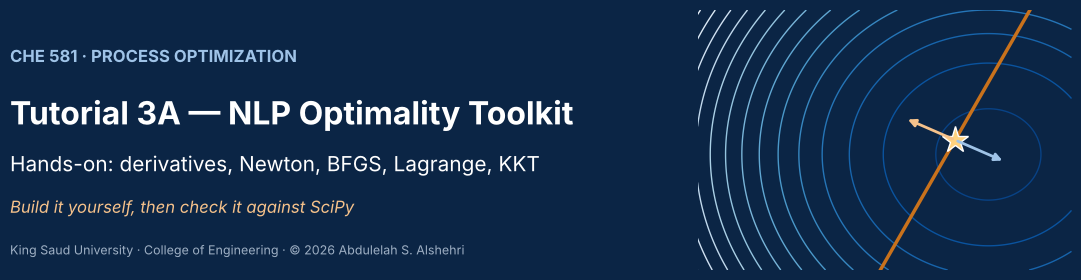

# Tutorial 3A — The NLP Optimality Toolkit
### CHE 581: Process Optimization · Module 3A companion
**College of Engineering — King Saud University** · Department of Chemical Engineering · Instructor: **Abdulelah S. Alshehri**

In the lecture we *derived* the optimality conditions. In this tutorial you **implement** them: you will write your own derivative checker, Newton and BFGS solvers, Lagrange and KKT tools, and an active-set QP solver, test each one against SciPy, and apply them to process problems.

> **How this notebook works**
> - Each exercise has a **= YOUR TURN** cell (a scaffold with `TODO`s) followed by a **✅ Solution** cell (collapsed in Colab; double-click to see the code).
> - Try the scaffold first. *Run all* is always safe: the scaffolds never crash, and the solution cells define everything later exercises need.

<sub>© 2026 Abdulelah S. Alshehri. All rights reserved.</sub>

## Contents

| # | Exercise | Skill | 🛠️ Application |
|---|---|---|---|
| 1 | Derivatives you can trust | symbolic vs. finite-difference gradients and Hessians | — |
| 2 | Classify stationary points | $\nabla f = 0$ + Hessian eigenvalues | — |
| 3 | Newton's method from scratch | quadratic convergence, basins of attraction | — |
| 4 | Line search & BFGS from scratch | Armijo backtracking, BFGS update, secant condition | Rosenbrock benchmark |
| 5 | Unconstrained process design | 1-D and n-D minimization | **multistage compressor with intercooling** |
| 6 | Lagrange multipliers | FONC, reduced Hessian, sensitivity | **storage tank with expensive heads** |
| 7 | A reusable KKT checker | stationarity, feasibility, complementarity | lecture exercises |
| 8 | An active-set QP solver | add / drop rules | worked example + exercise |
| 9 | Shadow prices | multipliers vs. re-optimization | **steam-limited production plan** |
| 10 | Non-convexity & multistart | local vs. global | **Haverly pooling, cases 1–3** |

In [ ]:
# ⚙️ Setup
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
import itertools, warnings; warnings.filterwarnings("ignore")

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(581)
NAVY, BLUE, GOLD, TEAL, RED, PURPLE, GRAY = "#0B2545", "#1F6FB2", "#C9721C", "#109C8F", "#C93C3C", "#7B4FA0", "#8D99AE"
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

def contour(f, xlim, ylim, ax=None, levels=30, log=False, n=250):
    """Quick contour plot of f([x1, x2]) on a box."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    Z = f([X, Y]); Z = np.log10(Z - Z.min() + 1e-2) if log else Z
    ax.contour(X, Y, Z, levels=levels, cmap="Blues_r", linewidths=0.8)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return ax
print("✅ Setup complete")

✅ Setup complete


---
## Exercise 1 — Derivatives you can trust

Every NLP algorithm needs $\nabla f$ (and often $\nabla^2 f$). Wrong derivatives are the **#1 reason solvers fail**, so always **check them against finite differences**:

$$\frac{\partial f}{\partial x_i} \approx \frac{f(x + h e_i) - f(x - h e_i)}{2h} \quad (\text{error } O(h^2)), \qquad h \approx 10^{-6}$$

**Tasks**
1. Write `num_grad(f, x, h)` (central differences) and `num_hess(f, x, h)`.
2. For $f(x) = x_1 e^{-x_2} + x_2^2 + \sin(x_1 x_2)$, get the exact gradient and Hessian with SymPy and compare at $x = (1, 0.5)$.

In [ ]:
#  YOUR TURN — Exercise 1: finite-difference derivatives
def num_grad(f, x, h=1e-6):
    x = np.asarray(x, float); g = np.zeros_like(x)
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = h
        # TODO: g[i] = central difference using f(x + e) and f(x - e)
    return g

def num_hess(f, x, h=1e-4):
    x = np.asarray(x, float); n = x.size; H = np.zeros((n, n))
    # TODO: differentiate num_grad column by column:  H[:, j] = (∇f(x + h e_j) − ∇f(x − h e_j)) / 2h
    return H

exact  ∇f = [1.0453 1.2711]
FD     ∇f = [1.0453 1.2711]    max error = 9.5e-11
exact ∇²f =
 [[-0.1199  0.0313]
 [ 0.0313  2.1271]]
FD    ∇²f =
 [[-0.1199  0.0313]
 [ 0.0313  2.1271]] 
max error = 3.1e-07


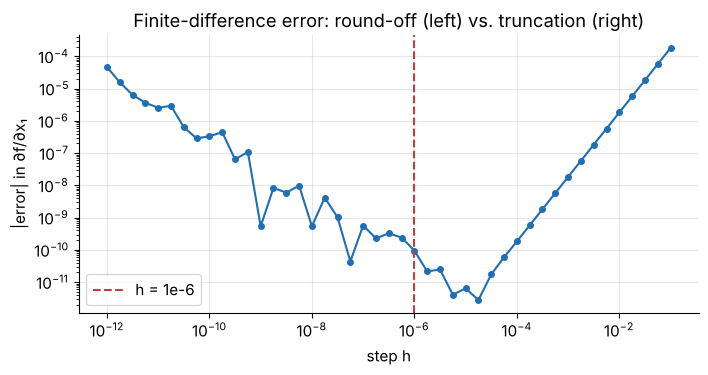

In [ ]:
# @title ✅ Solution — Exercise 1  (double-click to show the code)
def num_grad(f, x, h=1e-6):
    x = np.asarray(x, float); g = np.zeros_like(x)
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = h
        g[i] = (f(x + e) - f(x - e)) / (2*h)
    return g

def num_hess(f, x, h=1e-4):
    x = np.asarray(x, float); n = x.size; H = np.zeros((n, n))
    for j in range(n):
        e = np.zeros(n); e[j] = h
        H[:, j] = (num_grad(f, x + e) - num_grad(f, x - e)) / (2*h)
    return 0.5*(H + H.T)                                  # symmetrize

# exact derivatives with SymPy
x1, x2 = sp.symbols("x1 x2", real=True)
fs = x1*sp.exp(-x2) + x2**2 + sp.sin(x1*x2)
g_exact = sp.lambdify([x1, x2], [sp.diff(fs, v) for v in (x1, x2)])
H_exact = sp.lambdify([x1, x2], sp.hessian(fs, (x1, x2)))
f_num   = sp.lambdify([x1, x2], fs)
f = lambda x: f_num(x[0], x[1])

x0 = np.array([1.0, 0.5])
print("exact  ∇f =", np.array(g_exact(*x0)))
print("FD     ∇f =", num_grad(f, x0), "   max error =", f"{np.abs(num_grad(f, x0) - g_exact(*x0)).max():.1e}")
print("exact ∇²f =\n", np.array(H_exact(*x0)))
print("FD    ∇²f =\n", num_hess(f, x0), "\nmax error =", f"{np.abs(num_hess(f, x0) - np.array(H_exact(*x0))).max():.1e}")

# how does the error depend on h?  (truncation error ↓ with h, round-off error ↑ as h → 0)
hs = np.logspace(-12, -1, 45)
err = [abs(num_grad(f, x0, h)[0] - g_exact(*x0)[0]) for h in hs]
plt.loglog(hs, err, "o-", color=BLUE, ms=4); plt.axvline(1e-6, color=RED, ls="--", label="h = 1e-6")
plt.xlabel("step h"); plt.ylabel("|error| in ∂f/∂x₁"); plt.title("Finite-difference error: round-off (left) vs. truncation (right)")
plt.legend(); plt.show()

 The V-shaped error curve is universal: too large an $h$ gives truncation error $O(h^2)$, too small gives cancellation (round-off) error $O(\varepsilon_{mach}/h)$. Central differences with $h \approx 10^{-6}$ give about 10 correct digits, which is good enough to **check** analytic derivatives. Real solvers prefer exact derivatives (hand-coded, symbolic, or automatic differentiation, as in Pyomo/CasADi/JAX).

---
## Exercise 2 — Find and classify every stationary point

**Task:** write `classify(f, vars)` that (i) solves $\nabla f = 0$ symbolically, (ii) keeps the real roots, and (iii) labels each as **minimum / maximum / saddle / inconclusive** from the Hessian eigenvalues. Test it on

$$f(x, y) = x^4 + y^4 - 4xy$$

In [ ]:
#  YOUR TURN — Exercise 2: classify stationary points
def classify(f, vars):
    grad = [sp.diff(f, v) for v in vars]
    H = sp.hessian(f, vars)
    results = []
    # TODO: loop over sp.solve(grad, vars, dict=True); skip non-real roots
    # TODO: eigenvalues: np.linalg.eigvalsh(np.array(H.subs(s), dtype=float))
    # TODO: append (point, eigenvalues, label) to results
    return results

point [-1. -1.]   eigenvalues [ 8. 16.]   →  MINIMUM
point [0. 0.]   eigenvalues [-4.  4.]   →  SADDLE
point [1. 1.]   eigenvalues [ 8. 16.]   →  MINIMUM


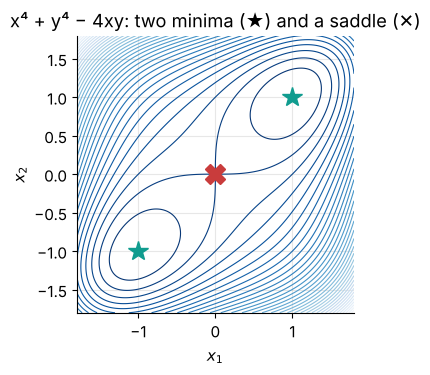

In [ ]:
# @title ✅ Solution — Exercise 2  (double-click to show the code)
def classify(f, vars, tol=1e-10):
    grad = [sp.diff(f, v) for v in vars]
    H = sp.hessian(f, vars)
    results = []
    for s in sp.solve(grad, vars, dict=True):
        if not all(sp.im(s[v]) == 0 for v in vars):
            continue
        pt = tuple(float(s[v]) for v in vars)
        ev = np.linalg.eigvalsh(np.array(H.subs(s), dtype=float))
        label = ("MINIMUM" if ev.min() > tol else "MAXIMUM" if ev.max() < -tol
                 else "SADDLE" if ev.min() < -tol and ev.max() > tol else "INCONCLUSIVE")
        results.append((pt, ev, label))
    return results

x, y = sp.symbols("x y", real=True)
fxy = x**4 + y**4 - 4*x*y
for pt, ev, lab in classify(fxy, (x, y)):
    print(f"point {np.round(pt, 3)}   eigenvalues {np.round(ev, 2)}   →  {lab}")

fl = sp.lambdify((x, y), fxy)
ax = contour(lambda z: fl(z[0], z[1]), (-1.8, 1.8), (-1.8, 1.8), levels=40)
for pt, ev, lab in classify(fxy, (x, y)):
    ax.plot(*pt, "*" if lab == "MINIMUM" else "X", ms=15, color=TEAL if lab == "MINIMUM" else RED)
ax.set_aspect("equal"); ax.set_title("x⁴ + y⁴ − 4xy: two minima (★) and a saddle (✕)"); plt.show()

 $\nabla f = 0$ at **three** points, but only two are minima. A gradient-based solver started on the diagonal $x = -y$ can stall at the saddle $(0, 0)$, which is why practical solvers check curvature or perturb the iterate.

 **Challenge:** run `classify` on $f = x^2 y^2$. Why is every point on the axes "inconclusive"? (The Hessian has a zero eigenvalue there: the second-order test cannot decide, even though they are all global minima.)

---
## Exercise 3 — Newton's method from scratch

$$x_{k+1} = x_k - \big[\nabla^2 f(x_k)\big]^{-1} \nabla f(x_k)$$

**Tasks**
1. Implement `newton(grad, hess, x0, tol, kmax)` that returns the whole history of iterates (use `np.linalg.solve`, never an explicit inverse).
2. Verify **quadratic convergence** on $f(x) = x^4 - 3x^2 + x$ from $x_0 = 2$: the ratio $e_{k+1}/e_k^2$ should approach a constant.
3. Draw the **basins of attraction**: run Newton from 400 starting points in $[-2, 2]$ and color each start by the stationary point it reaches.

In [ ]:
#  YOUR TURN — Exercise 3: Newton's method
def newton(grad, hess, x0, tol=1e-12, kmax=50):
    x = np.atleast_1d(np.asarray(x0, float)); hist = [x.copy()]
    for k in range(kmax):
        g = np.atleast_1d(grad(x))
        if np.linalg.norm(g) < tol:
            break
        # TODO: p = solve  H p = −g   with H = np.atleast_2d(hess(x))
        # TODO: x = x + p ; hist.append(x.copy())
        break
    return np.array(hist)

 k        x_k           e_k        e_(k+1)/e_k²
 0  2.000000000000   8.69e-01      0.489
 1  1.500000000000   3.69e-01      0.787
 2  1.238095238095   1.07e-01      1.164
 3  1.144277176659   1.34e-02      1.408
 4  1.131153090106   2.52e-04      1.451
 5  1.130901214751   9.21e-08      nan
theory: e_(k+1)/e_k² → |f'''(x*)/(2 f''(x*))| = 1.452


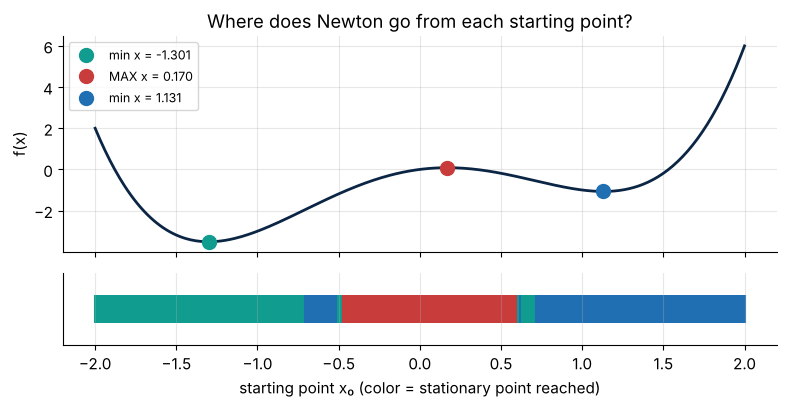

fraction of starts that converge to the MAXIMUM: 27%


In [ ]:
# @title ✅ Solution — Exercise 3  (double-click to show the code)
def newton(grad, hess, x0, tol=1e-12, kmax=50):
    x = np.atleast_1d(np.asarray(x0, float)); hist = [x.copy()]
    for k in range(kmax):
        g = np.atleast_1d(grad(x))
        if np.linalg.norm(g) < tol:
            break
        p = np.linalg.solve(np.atleast_2d(hess(x)), -g)
        x = x + p; hist.append(x.copy())
    return np.array(hist)

fp  = lambda x: 4*x**3 - 6*x + 1
fpp = lambda x: 12*x**2 - 6
H1 = newton(fp, fpp, 2.0)[:, 0]
xs = H1[-1]; e = np.abs(H1 - xs)
print(" k        x_k           e_k        e_(k+1)/e_k²")
for k in range(len(H1) - 1):
    ratio = e[k+1]/e[k]**2 if e[k] > 1e-15 and e[k+1] > 0 else np.nan
    print(f"{k:2d}  {H1[k]:.12f}   {e[k]:.2e}      {ratio:.3f}")
print(f"theory: e_(k+1)/e_k² → |f'''(x*)/(2 f''(x*))| = {abs(24*xs/(2*fpp(xs))):.3f}")

# basins of attraction
roots = np.sort(np.roots([4, 0, -6, 1]).real)            # the three stationary points
starts = np.linspace(-2, 2, 400)
ends = np.array([newton(fp, fpp, s, kmax=60)[-1, 0] for s in starts])
idx = np.array([np.argmin(abs(roots - v)) for v in ends])
cols = np.array([TEAL, RED, BLUE])
fig, ax = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
xx = np.linspace(-2, 2, 400); ax[0].plot(xx, xx**4 - 3*xx**2 + xx, color=NAVY, lw=2)
for r, c, lab in zip(roots, cols, ["min x = %.3f", "MAX x = %.3f", "min x = %.3f"]):
    ax[0].plot(r, r**4 - 3*r**2 + r, "o", color=c, ms=10, label=lab % r)
ax[0].legend(fontsize=9); ax[0].set_ylabel("f(x)"); ax[0].set_title("Where does Newton go from each starting point?")
ax[1].scatter(starts, np.zeros_like(starts), c=cols[idx], marker="|", s=400); ax[1].set_yticks([])
ax[1].set_xlabel("starting point x₀ (color = stationary point reached)"); plt.tight_layout(); plt.show()
print(f"fraction of starts that converge to the MAXIMUM: {np.mean(idx == 1):.0%}")

 Two lessons. (1) **Quadratic convergence**: the error is squared every step, and the ratio settles at $|f'''/(2f'')|$. (2) Pure Newton is **attracted to any stationary point**: more than a quarter of all starts end at the *maximum* (red), and the basins are not even simple intervals near the points where $f'' = 0$. A robust solver adds a positive-definite Hessian modification and a line search (next exercise).

---
## Exercise 4 — Line search and BFGS from scratch

**Armijo backtracking:** start with $\alpha = 1$ and halve it until $\;f(x + \alpha p) \le f(x) + c_1\, \alpha\, \nabla f(x)^\top p\;$ with $c_1 = 10^{-4}$.

**BFGS (inverse form):** with $s = x_{k+1} - x_k$, $y = \nabla f_{k+1} - \nabla f_k$, $\rho = 1/(y^\top s)$:

$$H_{k+1} = (I - \rho\, s y^\top)\, H_k\, (I - \rho\, y s^\top) + \rho\, s s^\top, \qquad p_k = -H_k \nabla f_k$$

**Tasks**
1. Implement `backtrack(f, x, p, g)` and `bfgs(f, grad, x0)`; return the iterate history.
2. Check the **secant condition** $H_{k+1} y = s$ after one update.
3. Race your BFGS against SciPy's BFGS and steepest descent (with your line search) on Rosenbrock from $(-1.2, 1)$.

In [ ]:
#  YOUR TURN — Exercise 4: Armijo line search + BFGS
def backtrack(f, x, p, g, c1=1e-4, alpha=1.0):
    # TODO: while f(x + alpha p) > f(x) + c1 alpha gᵀp :  alpha *= 0.5
    return alpha

def bfgs(f, grad, x0, tol=1e-8, kmax=500):
    x = np.asarray(x0, float); H = np.eye(x.size); hist = [x.copy()]
    g = grad(x)
    for k in range(kmax):
        if np.linalg.norm(g) < tol: break
        p = -H @ g
        # TODO: alpha = backtrack(...);  s = alpha p;  x_new = x + s;  y = grad(x_new) − g
        # TODO: BFGS update of H (skip it if yᵀs <= 1e-12 to keep H positive definite)
        break
    return np.array(hist)

secant check  H₁y − s = [ 0. -0.]   (should be ~0)
my BFGS      :   35 iterations → x = [1. 1.]
SciPy BFGS   :   32 iterations → x = [1. 1.]
steepest desc: 2000 iterations → x = [0.9887 0.9774]  (still not there)
final H vs. true inverse Hessian at x*:
 [[0.495 0.989]
 [0.989 1.983]] 
 [[0.5   1.   ]
 [1.    2.005]]


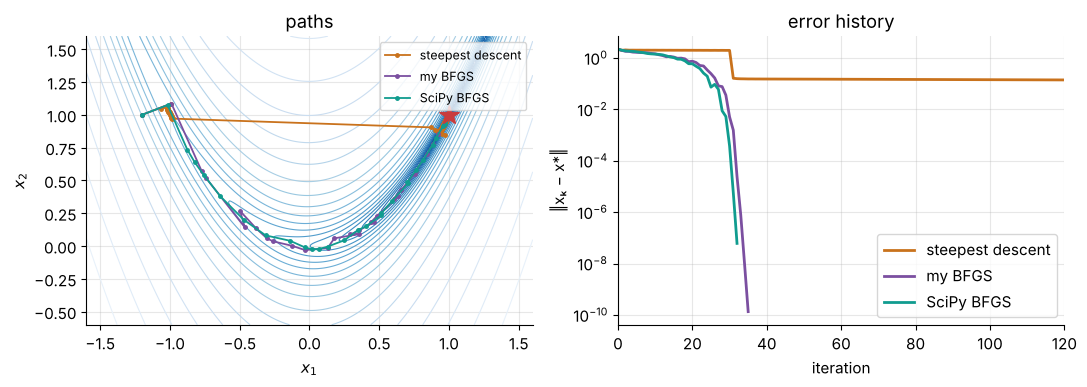

In [ ]:
# @title ✅ Solution — Exercise 4  (double-click to show the code)
def backtrack(f, x, p, g, c1=1e-4, alpha=1.0):
    fx = f(x)
    while not (f(x + alpha*p) <= fx + c1*alpha*(g @ p)) and alpha > 1e-12:   # 'not <=' also rejects NaN/inf
        alpha *= 0.5
    return alpha

def bfgs(f, grad, x0, tol=1e-8, kmax=500):
    x = np.asarray(x0, float); n = x.size; H = np.eye(n); hist = [x.copy()]
    g = grad(x)
    for k in range(kmax):
        if np.linalg.norm(g) < tol: break
        p = -H @ g
        alpha = backtrack(f, x, p, g)
        s = alpha*p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if y @ s > 1e-12:                                # curvature condition keeps H ≻ 0
            rho = 1.0/(y @ s); I = np.eye(n)
            H = (I - rho*np.outer(s, y)) @ H @ (I - rho*np.outer(y, s)) + rho*np.outer(s, s)
        x, g = x_new, g_new; hist.append(x.copy())
    return np.array(hist), H

rosen   = lambda x: (1 - x[0])**2 + 100*(x[1] - x[0]**2)**2
rosen_g = lambda x: np.array([-2*(1 - x[0]) - 400*x[0]*(x[1] - x[0]**2), 200*(x[1] - x[0]**2)])
x0 = np.array([-1.2, 1.0])

# (2) secant condition after one update
s = np.array([0.1, -0.05]); y = rosen_g(x0 + s) - rosen_g(x0); rho = 1/(y @ s); I = np.eye(2)
H1 = (I - rho*np.outer(s, y)) @ I @ (I - rho*np.outer(y, s)) + rho*np.outer(s, s)
print("secant check  H₁y − s =", H1 @ y - s, "  (should be ~0)")

# (3) the race
P_mine, H_final = bfgs(rosen, rosen_g, x0)
P_sp = [x0]; r = minimize(rosen, x0, jac=rosen_g, method="BFGS", callback=lambda xk: P_sp.append(xk.copy()))
P_sd = [x0]; x = x0.copy()
for k in range(2000):
    g = rosen_g(x); p = -g; x = x + backtrack(rosen, x, p, g)*p; P_sd.append(x.copy())
P_sd = np.array(P_sd)
print(f"my BFGS      : {len(P_mine)-1:4d} iterations → x = {P_mine[-1].round(6)}")
print(f"SciPy BFGS   : {r.nit:4d} iterations → x = {r.x.round(6)}")
print(f"steepest desc: 2000 iterations → x = {P_sd[-1].round(4)}  (still not there)")
print("final H vs. true inverse Hessian at x*:\n", H_final.round(3), "\n", np.linalg.inv(np.array([[802, -400], [-400, 200.]])).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
contour(rosen, (-1.6, 1.6), (-0.6, 1.6), ax=ax[0], log=True)
for P, c, lab in [(P_sd, GOLD, "steepest descent"), (P_mine, PURPLE, "my BFGS"), (np.array(P_sp), TEAL, "SciPy BFGS")]:
    ax[0].plot(P[:, 0], P[:, 1], "-o", ms=2.5, lw=1.3, color=c, label=lab)
    ax[1].semilogy(np.linalg.norm(P - 1, axis=1) + 1e-16, color=c, lw=2, label=lab)
ax[0].plot(1, 1, "*", color=RED, ms=15); ax[0].legend(fontsize=9); ax[0].set_title("paths")
ax[1].set_xlim(0, 120); ax[1].set_xlabel("iteration"); ax[1].set_ylabel("‖xₖ − x*‖"); ax[1].legend(); ax[1].set_title("error history")
plt.tight_layout(); plt.show()

💡 Your 20-line BFGS behaves like SciPy's, and its final $H_k$ is close to the **true inverse Hessian** at $x^*$: BFGS *learns* the curvature from gradients alone. Steepest descent with the same line search crawls, because the valley is badly conditioned ($\kappa(\nabla^2 f(x^*)) \approx 2500$).

---
## Exercise 5 — 🛠️ Multistage compressor with intercooling

Compressing a gas from $P_1$ to $P_{N+1}$ in $N$ adiabatic stages, with cooling back to $T_1$ between stages, needs (ideal gas, per mol):

$$W(P_2, \dots, P_N) = \frac{k}{k-1}\,R\,T_1 \sum_{i=1}^{N}\left[\left(\frac{P_{i+1}}{P_i}\right)^{(k-1)/k} - 1\right]$$

Data: $P_1 = 1$ bar, $P_{N+1} = 16$ bar, $T_1 = 300$ K, $k = 1.4$, $R = 8.314$ J/(mol·K).

**Tasks**
1. **Two stages:** minimize $W(P_2)$ with `minimize_scalar`, and show analytically (set $dW/dP_2 = 0$) that $P_2^* = \sqrt{P_1 P_3}$.
2. **Three stages:** minimize over $(P_2, P_3)$ with your `bfgs` (use `num_grad` for the gradient). Work in $u = \ln P$ so that pressures stay positive. Show that all stage pressure ratios are equal to $(P_{N+1}/P_1)^{1/N}$.
3. How much work does staging save compared with a single stage?

In [ ]:
#  YOUR TURN — Exercise 5: compressor staging
k, R, T1, P1, Pout = 1.4, 8.314, 300.0, 1.0, 16.0
def work(P):                         # P = full pressure list [P1, P2, ..., P_{N+1}]
    P = np.asarray(P, float)
    # TODO: return k/(k-1)*R*T1*sum((P[1:]/P[:-1])**((k-1)/k) - 1)
    return 0.0
# TODO 1: minimize_scalar(lambda P2: work([P1, P2, Pout]), bounds=(P1, Pout), method="bounded")
# TODO 2: bfgs(lambda u: work([P1, *np.exp(u), Pout])/1000, lambda u: num_grad(...), x0=np.log([3, 8]))
#         (optimizing u = ln P keeps the pressures positive and scales the problem nicely)

dW/dP2 = 0  →  P2* = [4] bar   (= √(P1·P3) = √16 = 4 bar)
2 stages: P2* = 4.0000 bar,  W = 8,485 J/mol
my BFGS converged in 7 iterations
3 stages: P = [ 1.      2.5198  6.3496 16.    ] bar,  ratios = [2.5198 2.5198 2.5198],  (16)^(1/3) = 2.5198
N = 1:  W =   10,547 J/mol   saving vs. 1 stage =  0.0%
N = 2:  W =    8,485 J/mol   saving vs. 1 stage = 19.5%
N = 3:  W =    7,914 J/mol   saving vs. 1 stage = 25.0%
N = 4:  W =    7,648 J/mol   saving vs. 1 stage = 27.5%
N = 5:  W =    7,493 J/mol   saving vs. 1 stage = 29.0%
N = 6:  W =    7,393 J/mol   saving vs. 1 stage = 29.9%


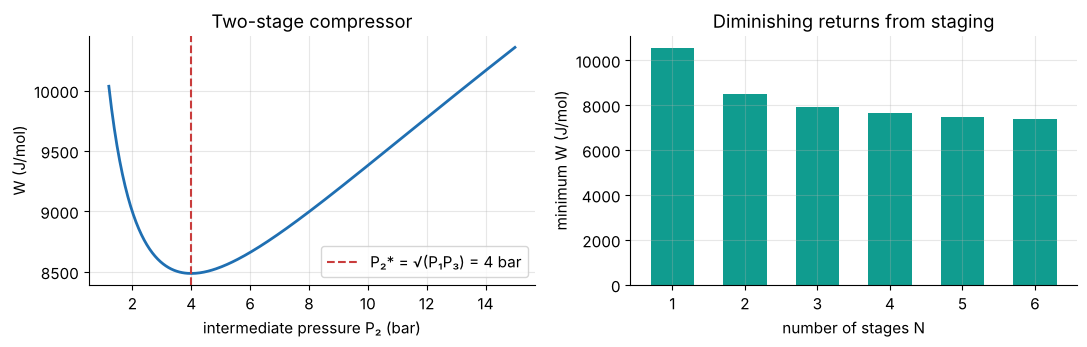

In [ ]:
# @title ✅ Solution — Exercise 5  (double-click to show the code)
k, R, T1, P1, Pout = 1.4, 8.314, 300.0, 1.0, 16.0
def work(P):
    P = np.asarray(P, float)
    return k/(k - 1)*R*T1*np.sum((P[1:]/P[:-1])**((k - 1)/k) - 1)

# (1) two stages: numerical + symbolic
r2 = minimize_scalar(lambda P2: work([P1, P2, Pout]), bounds=(P1, Pout), method="bounded")
P2s, a = sp.symbols("P2 a", positive=True)
W2 = (P2s/1)**a + (16/P2s)**a
roots = [p for p in sp.solve(sp.diff(W2, P2s).subs(a, sp.Rational(2, 7)), P2s) if p.is_real and p > 0]
print("dW/dP2 = 0  →  P2* =", roots, "bar   (= √(P1·P3) = √16 = 4 bar)")
print(f"2 stages: P2* = {r2.x:.4f} bar,  W = {r2.fun:,.0f} J/mol")

# (2) three stages with our own BFGS + finite-difference gradient.
#     Scaling trick: optimize u = ln P (always positive pressures) and W in kJ/mol (gradient of order 1)
W3 = lambda u: work([P1, *np.exp(u), Pout]) / 1000
U, _ = bfgs(W3, lambda u: num_grad(W3, u), x0=np.log([3.0, 8.0]))
z = np.exp(U[-1]); P = np.r_[P1, z, Pout]
print(f"my BFGS converged in {len(U)-1} iterations")
print(f"3 stages: P = {P.round(4)} bar,  ratios = {(P[1:]/P[:-1]).round(4)},  (16)^(1/3) = {16**(1/3):.4f}")

# (3) savings vs. number of stages
Ns = np.arange(1, 7); Wopt = [work(P1*(Pout/P1)**(np.arange(N + 1)/N)) for N in Ns]
for N, Wn in zip(Ns, Wopt):
    print(f"N = {N}:  W = {Wn:8,.0f} J/mol   saving vs. 1 stage = {1 - Wn/Wopt[0]:5.1%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
PP = np.linspace(1.2, 15, 300); ax[0].plot(PP, [work([P1, p, Pout]) for p in PP], color=BLUE, lw=2)
ax[0].axvline(4, color=RED, ls="--", label="P₂* = √(P₁P₃) = 4 bar"); ax[0].legend(); ax[0].set_xlabel("intermediate pressure P₂ (bar)")
ax[0].set_ylabel("W (J/mol)"); ax[0].set_title("Two-stage compressor")
ax[1].bar(Ns, Wopt, color=TEAL, width=0.6); ax[1].set_xlabel("number of stages N"); ax[1].set_ylabel("minimum W (J/mol)")
ax[1].set_title("Diminishing returns from staging"); plt.tight_layout(); plt.show()

 Equal pressure ratios are optimal: a classic design rule that falls straight out of $\nabla W = 0$. Two stages save about 20 % of the work, but each extra stage saves less, while capital cost (another compressor and intercooler) rises. The true optimum $N$ is a **trade-off**: with $N$ as an integer decision it becomes a mixed-integer NLP (later in the course).

---
## Exercise 6 — Lagrange multipliers: solve, classify, interpret

**Tasks**
1. Write `lagrange(f, hs, xs)` that builds $L = f + \sum \lambda_i h_i$, solves $\nabla_x L = 0,\; h = 0$, and returns each real solution with its **reduced Hessian** $Z^\top \nabla^2_{xx} L\, Z$ ($Z$ = null-space basis of $\nabla h^\top$).
2. Test it on $\min\, x_1^2 + x_2^2$ s.t. $x_1 + x_2 = 4$.
3. 🛠️ **Tank with expensive heads.** The shell costs $c_s = 1$ and the two heads cost $c_h = 2$ (per m²). Minimize $c_s\,2\pi r h + c_h\,2\pi r^2$ s.t. $\pi r^2 h = 50$ m³. Show that $h/D = c_h/c_s$, and check $-\lambda^* = dC^*/dV$ by re-solving at $V = 51$.

In [ ]:
#  YOUR TURN — Exercise 6: Lagrange solver
def lagrange(f, hs, xs):
    lams = sp.symbols(f"lambda1:{len(hs)+1}", real=True)
    L = f + sum(l*h for l, h in zip(lams, hs))
    eqs = [sp.diff(L, v) for v in xs] + list(hs)
    out = []
    # TODO: for s in sp.solve(eqs, list(xs) + list(lams), dict=True):
    #          J = sp.Matrix(hs).jacobian(xs).subs(s);  Z = null space of J (use sp.Matrix.hstack(*J.nullspace()))
    #          redH = Z.T * sp.hessian(L, xs).subs(s) * Z
    #          out.append((s, redH))
    return out

In [ ]:
# @title ✅ Solution — Exercise 6  (double-click to show the code)
def lagrange(f, hs, xs):
    lams = sp.symbols(f"lambda1:{len(hs)+1}", real=True)
    L = f + sum(l*h for l, h in zip(lams, hs))
    eqs = [sp.diff(L, v) for v in xs] + list(hs)
    out = []
    for s in sp.solve(eqs, list(xs) + list(lams), dict=True):
        if not all(sp.im(v) == 0 for v in s.values()):
            continue
        J = sp.Matrix(hs).jacobian(xs).subs(s)
        Z = sp.Matrix.hstack(*J.nullspace())
        redH = sp.simplify(Z.T * sp.hessian(L, xs).subs(s) * Z)
        out.append((s, redH))
    return out

# (2) textbook test
a1, a2 = sp.symbols("x1 x2", real=True)
for s, redH in lagrange(a1**2 + a2**2, [a1 + a2 - 4], (a1, a2)):
    print("solution:", s, "  reduced Hessian:", redH.tolist(), " → minimum" if all(e > 0 for e in redH.eigenvals()) else "")

# (3) tank with expensive heads (eliminate step by step to avoid complex cube roots)
r, h, V = sp.symbols("r h V", positive=True); lam = sp.symbols("lambda", real=True)
cs, ch = 1, 2
C = cs*2*sp.pi*r*h + ch*2*sp.pi*r**2
L = C + lam*(sp.pi*r**2*h - V)
lam_r = sp.solve(sp.diff(L, h), lam)[0]
h_r = sp.solve(sp.diff(L, r).subs(lam, lam_r), h)[0]
r_V = sp.solve((sp.pi*r**2*h - V).subs(h, h_r), r)[0]
print(f"\nh = {h_r}  →  h/D = {sp.simplify(h_r/(2*r))}  (= c_h/c_s = {ch/cs})")
Cstar = sp.lambdify(V, C.subs(h, h_r).subs(r, r_V)); lam_V = sp.lambdify(V, lam_r.subs(r, r_V))
print(f"V = 50 m³: r = {float(r_V.subs(V, 50)):.3f} m, h = {float(h_r.subs(r, r_V).subs(V, 50)):.3f} m, cost = {Cstar(50):.2f}")
print(f"−λ* = {-lam_V(50):.4f}   vs.   C*(51) − C*(50) = {Cstar(51) - Cstar(50):.4f}   ✓")

# numerical cross-check with SLSQP
res = minimize(lambda z: cs*2*np.pi*z[0]*z[1] + ch*2*np.pi*z[0]**2, [1, 1], method="SLSQP",
               constraints=[{"type": "eq", "fun": lambda z: np.pi*z[0]**2*z[1] - 50}], bounds=[(0.01, None)]*2,
               options={"ftol": 1e-12, "maxiter": 500})
print("SLSQP:", res.x.round(4), round(res.fun, 2))

solution: {lambda1: -4, x1: 2, x2: 2}   reduced Hessian: [[4]]  → minimum

h = 4*r  →  h/D = 2  (= c_h/c_s = 2.0)
V = 50 m³: r = 1.585 m, h = 6.338 m, cost = 94.66
−λ* = 1.2621   vs.   C*(51) − C*(50) = 1.2580   ✓
SLSQP: [1.5846 6.3384] 94.66


 A tank whose heads cost twice as much per m² should be **twice as tall as it is wide**. The multiplier is the **marginal cost of capacity**: about 1.26 cost units per extra m³ here. Engineers use exactly this number when deciding whether to build slightly bigger "for future expansion".

---
## Exercise 7 — A reusable KKT checker

Given a candidate $x^*$ for $\min f$ s.t. $h(x) = 0$, $g(x) \le 0$:
1. find the **active** inequalities ($|g_j| \le$ tol);
2. estimate the multipliers by least squares from stationarity, $\;\nabla f + J_h^\top\lambda + J_{g,A}^\top \mu_A = 0$;
3. report the four KKT residuals.

**Task:** write `kkt_check(...)` and use it on the two exercise NLPs from the lecture slides:

$$\text{(a)}\;\; \min\; x_1^2 + x_2^2 \;\;\text{s.t.}\;\; x_1^2 + x_2^2 \le 5,\;\; x_1 + 2x_2 = 4,\;\; x \ge 0 \qquad\quad \text{(b)}\;\; \max\; \ln(x_1 + 1) + x_2 \;\;\text{s.t.}\;\; 2x_1 + x_2 \le 3,\;\; x \ge 0$$

In [ ]:
#  YOUR TURN — Exercise 7: KKT checker
def kkt_check(grad_f, x, h_list=(), jac_h=(), g_list=(), jac_g=(), tol=1e-6):
    x = np.asarray(x, float)
    gvals = np.array([g(x) for g in g_list])
    active = [j for j, v in enumerate(gvals) if abs(v) <= tol]
    # TODO: build the matrix M = [∇h_1 ... ∇h_m  ∇g_j (j active)] (columns) and solve M m = −∇f by np.linalg.lstsq
    # TODO: split m into λ (first len(h_list)) and μ_active; put μ = 0 for inactive constraints
    # TODO: print stationarity ‖∇f + M m‖, max |h|, max(g, 0), min μ, max |μ_j g_j|
    return None

In [ ]:
# @title ✅ Solution — Exercise 7  (double-click to show the code)
def kkt_check(grad_f, x, h_list=(), jac_h=(), g_list=(), jac_g=(), tol=1e-6, name=""):
    x = np.asarray(x, float)
    hvals = np.array([h(x) for h in h_list]); gvals = np.array([g(x) for g in g_list])
    active = [j for j, v in enumerate(gvals) if abs(v) <= tol]
    cols = [np.asarray(J(x), float) for J in jac_h] + [np.asarray(jac_g[j](x), float) for j in active]
    M = np.column_stack(cols) if cols else np.zeros((x.size, 0))
    m = np.linalg.lstsq(M, -grad_f(x), rcond=None)[0] if cols else np.zeros(0)
    lam, mu = m[:len(h_list)], np.zeros(len(g_list)); mu[active] = m[len(h_list):]
    stat = np.linalg.norm(grad_f(x) + M @ m)
    rows = [("stationarity ‖∇L‖", stat, stat < 1e-5),
            ("primal: max |h|", np.abs(hvals).max() if hvals.size else 0, (np.abs(hvals).max() if hvals.size else 0) < 1e-6),
            ("primal: max g⁺", max(gvals.max(), 0) if gvals.size else 0, (max(gvals.max(), 0) if gvals.size else 0) < 1e-6),
            ("dual: min μ", mu.min() if mu.size else 0, (mu.min() if mu.size else 0) >= -1e-8),
            ("compl.: max |μ g|", np.abs(mu*gvals).max() if mu.size else 0, (np.abs(mu*gvals).max() if mu.size else 0) < 1e-6)]
    print(f"── KKT report {name}:  x = {x.round(5)}   active g: {[j+1 for j in active]}   λ = {lam.round(4)}   μ = {mu.round(4)}")
    for lab, val, ok in rows:
        print(f"   {lab:20s} {val:+.2e}   {'✓' if ok else '✗'}")
    return all(ok for *_, ok in rows)

# (a)
fa  = lambda x: x[0]**2 + x[1]**2
ra = minimize(fa, [1, 1], method="SLSQP", constraints=[{"type": "eq", "fun": lambda x: x[0] + 2*x[1] - 4},
              {"type": "ineq", "fun": lambda x: 5 - x[0]**2 - x[1]**2}], bounds=[(0, None)]*2, options={"ftol": 1e-12})
_ = kkt_check(lambda x: 2*x, ra.x, h_list=[lambda x: x[0] + 2*x[1] - 4], jac_h=[lambda x: [1, 2]],
          g_list=[lambda x: x[0]**2 + x[1]**2 - 5, lambda x: -x[0], lambda x: -x[1]],
          jac_g=[lambda x: [2*x[0], 2*x[1]], lambda x: [-1, 0], lambda x: [0, -1]], name="(a)")

# (b)  max ln(x1+1) + x2  ⇔  min −ln(x1+1) − x2
fb  = lambda x: -np.log(x[0] + 1) - x[1]
rb = minimize(fb, [0.5, 0.5], method="SLSQP", constraints=[{"type": "ineq", "fun": lambda x: 3 - 2*x[0] - x[1]}],
              bounds=[(0, None)]*2, options={"ftol": 1e-12})
_ = kkt_check(lambda x: np.array([-1/(x[0] + 1), -1.0]), rb.x,
          g_list=[lambda x: 2*x[0] + x[1] - 3, lambda x: -x[0], lambda x: -x[1]],
          jac_g=[lambda x: [2, 1], lambda x: [-1, 0], lambda x: [0, -1]], name="(b)")
print("\nA deliberately WRONG candidate for (b):")
_ = kkt_check(lambda x: np.array([-1/(x[0] + 1), -1.0]), [0.5, 2.0],
          g_list=[lambda x: 2*x[0] + x[1] - 3, lambda x: -x[0], lambda x: -x[1]],
          jac_g=[lambda x: [2, 1], lambda x: [-1, 0], lambda x: [0, -1]], name="(b, wrong)")

── KKT report (a):  x = [0.8 1.6]   active g: []   λ = [-1.6]   μ = [0. 0. 0.]
   stationarity ‖∇L‖    +2.55e-08   ✓
   primal: max |h|      +0.00e+00   ✓
   primal: max g⁺       +0.00e+00   ✓
   dual: min μ          +0.00e+00   ✓
   compl.: max |μ g|    +0.00e+00   ✓
── KKT report (b):  x = [0. 3.]   active g: [1, 2]   λ = []   μ = [1. 1. 0.]
   stationarity ‖∇L‖    +5.55e-16   ✓
   primal: max |h|      +0.00e+00   ✓
   primal: max g⁺       -0.00e+00   ✓
   dual: min μ          +0.00e+00   ✓
   compl.: max |μ g|    +3.69e-14   ✓

A deliberately WRONG candidate for (b):
── KKT report (b, wrong):  x = [0.5 2. ]   active g: [1]   λ = []   μ = [0.4667 0.     0.    ]
   stationarity ‖∇L‖    +5.96e-01   ✗
   primal: max |h|      +0.00e+00   ✓
   primal: max g⁺       +0.00e+00   ✓
   dual: min μ          +0.00e+00   ✓
   compl.: max |μ g|    +0.00e+00   ✓


 In (a) the **equality alone** pins the solution $(0.8, 1.6)$ and the disk constraint is slack ($\mu = 0$, $\lambda = -1.6$). In (b) the optimum $(0, 3)$ sits on **two** active constraints, the resource limit and the bound $x_1 \ge 0$, both with positive multipliers. The wrong candidate $(0.5, 2)$ is feasible and makes the resource limit active, but no multiplier can balance $\nabla f$ (stationarity residual ≈ 0.6): the checker rejects it.

---
## Exercise 8 — An active-set solver for convex QPs

For $\min \tfrac12 x^\top H x + c^\top x$ s.t. $Ax \le b$ with $H \succ 0$, each active-set guess $J$ is a **linear** KKT system:

$$\begin{bmatrix} H & A_J^\top \\ A_J & 0 \end{bmatrix} \begin{bmatrix} x \\ \mu_J \end{bmatrix} = \begin{bmatrix} -c \\ b_J \end{bmatrix}$$

**Rules (lecture, slide 20):** if some $\mu_j < 0$, drop the most negative; else if some $g_j > 0$, add the most violated; else STOP.

**Tasks:** implement `active_set_qp(H, c, A, b)`, reproduce the lecture's worked example, then solve the exercise

$$\min\; x_1^2 + x_2^2 - 3x_1 - 4x_2 + 10 \quad\text{s.t.}\quad x_1 - 2x_2 \le -1,\;\; x_1 + 2x_2 \le 4,\;\; x_1, x_2 \ge 0$$

In [ ]:
#  YOUR TURN — Exercise 8: active-set QP solver
def active_set_qp(H, c, A, b, J0=(), kmax=20, verbose=True):
    J = list(J0); hist = []
    for it in range(kmax):
        # TODO 1: assemble and solve the KKT system for the current J  → x, muJ
        # TODO 2: if any muJ < 0: drop J[argmin muJ]; continue
        # TODO 3: viol = A x − b; if viol.max() > 1e-9: add argmax viol; continue
        # TODO 4: otherwise return x, J, muJ, hist
        break
    return None

── Lecture worked example ──
iter 1: J = []       x = [3. 1.]            μ_J = []             max g = +0.500
iter 2: J = [2]      x = [2.6 1.2]          μ_J = [0.4]          max g = +0.000
x* = [2.6 1.2]  μ* = [0.  0.4 0. ]  f* = -4.8999999999999995

── Exercise (slide 78): min x1² + x2² − 3x1 − 4x2 + 10 ──
iter 1: J = []       x = [1.5 2. ]          μ_J = []             max g = +1.500
iter 2: J = [2]      x = [1.2 1.4]          μ_J = [0.6]          max g = +0.000
x* = [1.2 1.4]  μ* = [0.  0.6 0.  0. ]  f* = 4.200000000000001


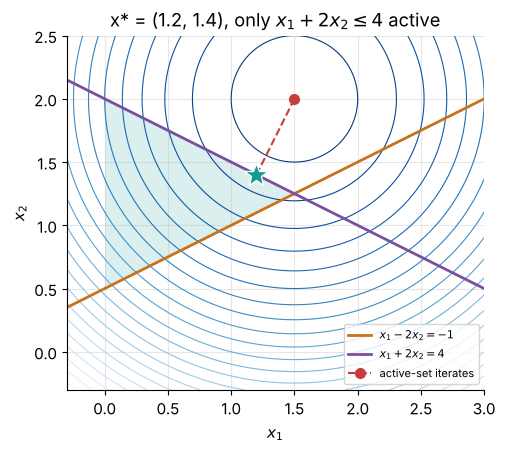

In [ ]:
# @title ✅ Solution — Exercise 8  (double-click to show the code)
def active_set_qp(H, c, A, b, J0=(), kmax=20, verbose=True):
    J = list(J0); hist = []; n = len(c)
    for it in range(1, kmax + 1):
        AJ = A[J]; K = np.block([[H, AJ.T], [AJ, np.zeros((len(J), len(J)))]])
        z = np.linalg.solve(K, np.r_[-c, b[J]]); x, muJ = z[:n], z[n:]
        viol = A @ x - b; hist.append(x.copy())
        if verbose:
            print(f"iter {it}: J = {[j+1 for j in J]!s:8s} x = {x.round(4)!s:18s} μ_J = {muJ.round(4)!s:14s} max g = {viol.max():+.3f}")
        if len(J) and muJ.min() < -1e-10:
            J.pop(int(np.argmin(muJ))); continue                     # drop the most negative multiplier
        if viol.max() > 1e-9:
            J.append(int(np.argmax(viol))); continue                 # add the most violated constraint
        mu = np.zeros(len(b)); mu[J] = muJ
        return x, mu, np.array(hist)
    raise RuntimeError("no convergence")

print("── Lecture worked example ──")
H = np.eye(2); c = np.array([-3., -1.]); A = np.array([[-1., 1.], [1., -0.5], [0., -1.]]); b = np.array([0., 2., 0.])
x, mu, _ = active_set_qp(H, c, A, b); print("x* =", x, " μ* =", mu, " f* =", 0.5*x@H@x + c@x)

print("\n── Exercise (slide 78): min x1² + x2² − 3x1 − 4x2 + 10 ──")
H2 = 2*np.eye(2); c2 = np.array([-3., -4.])
A2 = np.array([[1., -2.], [1., 2.], [-1., 0.], [0., -1.]]); b2 = np.array([-1., 4., 0., 0.])
x2s, mu2, hist2 = active_set_qp(H2, c2, A2, b2)
print("x* =", x2s, " μ* =", mu2, " f* =", 0.5*x2s@H2@x2s + c2@x2s + 10)

# picture
plt.figure(figsize=(6.2, 4.6))
ax = contour(lambda z: z[0]**2 + z[1]**2 - 3*z[0] - 4*z[1] + 10, (-0.3, 3), (-0.3, 2.5), levels=25)
xx = np.linspace(-0.3, 3, 50)
ax.plot(xx, (xx + 1)/2, color=GOLD, lw=2, label="$x_1 - 2x_2 = -1$"); ax.plot(xx, (4 - xx)/2, color=PURPLE, lw=2, label="$x_1 + 2x_2 = 4$")
Xg, Yg = np.meshgrid(np.linspace(-0.3, 3, 300), np.linspace(-0.3, 2.5, 300))
ax.contourf(Xg, Yg, ((Xg - 2*Yg <= -1) & (Xg + 2*Yg <= 4) & (Xg >= 0) & (Yg >= 0)).astype(float), levels=[0.5, 1.5], colors=[TEAL], alpha=0.15)
ax.plot(hist2[:, 0], hist2[:, 1], "--o", color=RED, ms=7, label="active-set iterates"); ax.plot(*x2s, "*", color=TEAL, ms=18, mec="white")
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower right"); ax.set_title("x* = (1.2, 1.4), only $x_1 + 2x_2 \\leq 4$ active"); plt.show()

 Two iterations each: the unconstrained minimum $(1.5, 2)$ violates $x_1 + 2x_2 \le 4$, which is added, and the multiplier $\mu = 0.6 > 0$ confirms it. Because $H \succ 0$ and the constraints are linear, the KKT point is the **unique global** optimum. Real QP solvers (e.g., in SQP codes) use exactly this logic with clever matrix updates.

---
## Exercise 9 —  Shadow prices: is the extra boiler worth renting?

A plant makes products 1 and 2 ($x_1, x_2$ in t/h). Prices fall as output rises, so the profit is concave:

$$\max\; P(x) = 40x_1 - 0.5x_1^2 + 30x_2 - 0.4x_2^2 \;\; [\$/h] \qquad \text{s.t.} \qquad \underbrace{2x_1 + x_2 \le 40}_{\text{steam, t/h}}, \quad \underbrace{x_1 + 2x_2 \le 50}_{\text{cooling water}}, \quad x \ge 0$$

**Tasks**
1. Solve it, find the multipliers with your `kkt_check`, and identify the **bottleneck**.
2. A contractor rents a package boiler giving **+5 t/h of steam for \$50/h**. Predict the gain with the shadow price, then **re-optimize** to get the true gain. Explain the difference.

In [ ]:
#  YOUR TURN — Exercise 9: shadow prices
P = lambda x: 40*x[0] - 0.5*x[0]**2 + 30*x[1] - 0.4*x[1]**2
def plan(steam=40.0, cooling=50.0):
    # TODO: minimize −P with SLSQP subject to steam and cooling limits (x >= 0) and return the result
    pass
# TODO: kkt_check(...) at the solution → μ_steam, μ_cooling
# TODO: compare 5·μ_steam with P(plan(45).x) − P(plan(40).x)

base plan: x = [10.476 19.048] t/h, profit = 790.48 $/h
── KKT report (plan):  x = [10.4762 19.0476]   active g: [1]   λ = []   μ = [14.7619  0.      0.      0.    ]
   stationarity ‖∇L‖    +8.30e-07   ✓
   primal: max |h|      +0.00e+00   ✓
   primal: max g⁺       +0.00e+00   ✓
   dual: min μ          +0.00e+00   ✓
   compl.: max |μ g|    +0.00e+00   ✓

shadow price of steam μ = 14.76 $/h per t/h   → predicted gain for +5 t/h: 73.8 $/h
re-optimized at 45 t/h: x = [13.333 18.333], profit = 860.00 $/h  → true gain = 69.5 $/h
cooling water used at 45 t/h steam: 50.00 of 50  ← it becomes ACTIVE
net benefit of renting the boiler: +19.5 $/h


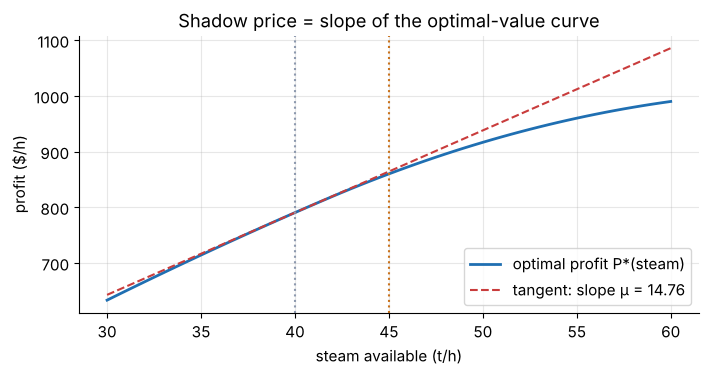

In [ ]:
# @title ✅ Solution — Exercise 9  (double-click to show the code)
P = lambda x: 40*x[0] - 0.5*x[0]**2 + 30*x[1] - 0.4*x[1]**2
def plan(steam=40.0, cooling=50.0):
    cons = [{"type": "ineq", "fun": lambda x: steam - 2*x[0] - x[1]},
            {"type": "ineq", "fun": lambda x: cooling - x[0] - 2*x[1]}]
    return minimize(lambda x: -P(x), [1, 1], method="SLSQP", constraints=cons, bounds=[(0, None)]*2, options={"ftol": 1e-12})

base = plan()
print(f"base plan: x = {base.x.round(3)} t/h, profit = {-base.fun:.2f} $/h")
_ = kkt_check(lambda x: -np.array([40 - x[0], 30 - 0.8*x[1]]), base.x,
          g_list=[lambda x: 2*x[0] + x[1] - 40, lambda x: x[0] + 2*x[1] - 50, lambda x: -x[0], lambda x: -x[1]],
          jac_g=[lambda x: [2, 1], lambda x: [1, 2], lambda x: [-1, 0], lambda x: [0, -1]], name="(plan)")
mu_steam = (40 - base.x[0])/2                                  # from stationarity in x1
print(f"\nshadow price of steam μ = {mu_steam:.2f} $/h per t/h   → predicted gain for +5 t/h: {5*mu_steam:.1f} $/h")

steams = np.linspace(30, 60, 61); profits = np.array([-plan(s).fun for s in steams])
new = plan(45); print(f"re-optimized at 45 t/h: x = {new.x.round(3)}, profit = {-new.fun:.2f} $/h  → true gain = {-new.fun + base.fun:.1f} $/h")
print(f"cooling water used at 45 t/h steam: {new.x[0] + 2*new.x[1]:.2f} of 50  ← it becomes ACTIVE")
print(f"net benefit of renting the boiler: {-new.fun + base.fun - 50:+.1f} $/h")

plt.plot(steams, profits, color=BLUE, lw=2, label="optimal profit P*(steam)")
plt.plot(steams, -base.fun + mu_steam*(steams - 40), "--", color=RED, label=f"tangent: slope μ = {mu_steam:.2f}")
plt.axvline(40, color=GRAY, ls=":"); plt.axvline(45, color=GOLD, ls=":")
plt.xlabel("steam available (t/h)"); plt.ylabel("profit ($/h)"); plt.legend(); plt.title("Shadow price = slope of the optimal-value curve"); plt.show()

 Steam is the bottleneck ($\mu \approx 14.8$ \$/h per t/h) and cooling water is free to relax ($\mu = 0$). The shadow-price prediction (≈ 74 \$/h) **overestimates** the true gain (≈ 70 \$/h) for two reasons: the profit curve is **concave** (diminishing returns), and at about 41.7 t/h the **cooling-water constraint becomes active**, which bends the curve. Shadow prices are exact only for **small** changes that keep the same active set. The boiler is still worth renting (+20 \$/h net).

---
## Exercise 10 — 🛠️ Non-convexity and multistart: the Haverly pooling cases

**Tasks**
1. Write a generic `multistart(solve_once, sampler, n)` that returns all solutions found.
2. Solve **Haverly case 1** (lecture), **case 2** (demand of X raised to 600) and **case 3** (crude B cost lowered to \$13). Report how often the **global** optimum is found.
3. Discuss: what fraction of single runs would leave money on the table?

In [ ]:
#  YOUR TURN — Exercise 10: multistart
def multistart(solve_once, sampler, n=60):
    results = []
    # TODO: for i in range(n): x0 = sampler(); r = solve_once(x0); keep (rounded objective, x) when r.success
    return results

Case 1 (base)            optima found: $0 ×3,  $100 ×10,  $400 ×47        global = $400   hit rate = 78%   best q = 1.00 %S


Case 2 (X demand 600)    optima found: $0 ×3,  $400 ×47,  $600 ×10        global = $600   hit rate = 17%   best q = 3.00 %S


Case 3 (B costs $13)     optima found: $0 ×4,  $125 ×7,  $750 ×49         global = $750   hit rate = 82%   best q = 1.50 %S


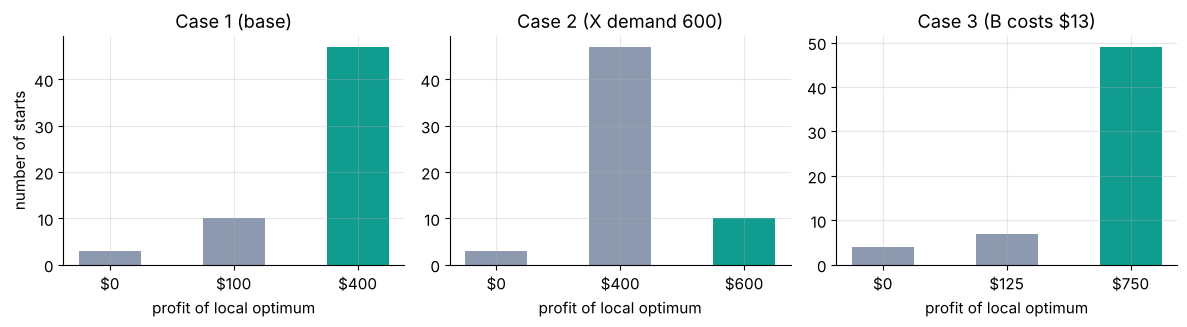

In [ ]:
# @title ✅ Solution — Exercise 10  (double-click to show the code)
def multistart(solve_once, sampler, n=60):
    results = []
    for i in range(n):
        r = solve_once(sampler())
        if r.success:
            results.append((round(-r.fun, 1) + 0.0, r.x))
    return results

def haverly(dX=100.0, cB=16.0):
    profit = lambda x: 9*(x[4] + x[2]) + 15*(x[5] + x[3]) - 6*x[0] - cB*x[1] - 10*(x[2] + x[3])
    cons = [{"type": "eq",   "fun": lambda x: x[0] + x[1] - x[4] - x[5]},
            {"type": "eq",   "fun": lambda x: 3*x[0] + x[1] - x[6]*(x[4] + x[5])},
            {"type": "ineq", "fun": lambda x: dX - x[4] - x[2]},
            {"type": "ineq", "fun": lambda x: 200 - x[5] - x[3]},
            {"type": "ineq", "fun": lambda x: 2.5*(x[4] + x[2]) - x[6]*x[4] - 2*x[2]},
            {"type": "ineq", "fun": lambda x: 1.5*(x[5] + x[3]) - x[6]*x[5] - 2*x[3]}]
    bnds = [(0, 700)]*6 + [(1, 3)]
    opts = {"maxiter": 500, "ftol": 1e-11}
    def solve_once(x0):                                  # solve + warm restart (removes premature stops)
        r = minimize(lambda x: -profit(x), x0, method="SLSQP", bounds=bnds, constraints=cons, options=opts)
        return minimize(lambda x: -profit(x), r.x, method="SLSQP", bounds=bnds, constraints=cons, options=opts)
    return solve_once

sampler = lambda: np.r_[rng.uniform(0, 200, 6), rng.uniform(1, 3)]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, kw) in zip(axs, [("Case 1 (base)", {}), ("Case 2 (X demand 600)", {"dX": 600}), ("Case 3 (B costs $13)", {"cB": 13})]):
    res = multistart(haverly(**kw), sampler, n=60)
    vals, counts = np.unique([v for v, _ in res], return_counts=True)
    best = vals.max(); xb = max(res, key=lambda t: t[0])[1]
    found = ",  ".join(f"${v:.0f} ×{n}" for v, n in zip(vals, counts))
    print(f"{name:24s} optima found: {found:34s} global = ${best:.0f}   "
          f"hit rate = {counts[-1]/len(res):.0%}   best q = {xb[6]:.2f} %S")
    ax.bar([f"${v:.0f}" for v in vals], counts, color=[TEAL if v == best else GRAY for v in vals], width=0.5)
    ax.set_title(name); ax.set_xlabel("profit of local optimum")
axs[0].set_ylabel("number of starts"); plt.tight_layout(); plt.show()

 Case 2 is the most striking: most starts return the \$400 plan, which is **feasible, KKT and "successful"**, while the global plan earns \$600. The global solution runs the pool at a **different quality** $q$, a different "basin" of the bilinear landscape. With fewer than 1 start in 5 finding it, a single run is very likely to leave money on the table, so **never trust a single local solve of a non-convex model**.

 **Challenge:** replace random starts with a smart guess: fix $q$ on a grid (1.0, 1.1, …, 3.0). With $q$ fixed, the model is an **LP** (the bilinear terms become linear). Solve each LP with `scipy.optimize.linprog` and keep the best. This "fix the complicating variable" trick is the idea behind many global pooling algorithms.

---
##  Wrap-up: what you built

| Tool | You can now… |
|---|---|
| `num_grad`, `num_hess` | verify any analytic derivative before trusting a solver |
| `classify` | find and label all stationary points of small models |
| `newton`, `bfgs`, `backtrack` | explain *why* solvers converge fast (or don't) |
| `lagrange` | solve equality-constrained designs and read $\lambda$ as a marginal cost |
| `kkt_check` | certify (or reject) a solver's answer, and get its shadow prices |
| `active_set_qp` | solve convex QPs exactly, the core of SQP (Module 3B) |
| `multistart` | protect yourself against non-convex traps |

**Self-check before Module 3B**
1. Why does Newton sometimes converge to a maximum, and how do practical codes prevent it?
2. What do $\mu_j = 0$ and $g_j < 0$ together tell you about constraint $j$?
3. When is a KKT point guaranteed to be the **global** optimum?
4. Why did the shadow-price estimate in Exercise 9 overpredict the true gain?

---
<div align="center">

**© 2026 Abdulelah S. Alshehri. All rights reserved.**<br>
CHE 581: Process Optimization · Department of Chemical Engineering · College of Engineering — King Saud University<br>
<sub>This material may not be reproduced or distributed without written permission of the author.</sub>

</div>

---
<div align="center">

**© 2026 Abdulelah S. Alshehri. All rights reserved.**<br>
CHE 581: Process Optimization · Department of Chemical Engineering · College of Engineering — King Saud University<br>
<sub>This material may not be reproduced or distributed without written permission of the author.</sub>

</div>